In [ ]:
# ===== Standard library =====
import csv
import datetime
import glob
import os
import random
import re
from collections import Counter
from datetime import timedelta

# ===== Numerical & data handling =====
import numpy as np
import pandas as pd
import polars as pl
from numpy.random import default_rng

# ===== Visualization =====
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

# ===== Scikit-learn =====
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    auc,
    average_precision_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GroupShuffleSplit, KFold, train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.utils import shuffle
from sklearn.utils.class_weight import compute_class_weight

# ===== Imbalanced-learn =====
from imblearn.under_sampling import RandomUnderSampler

# ===== Keras =====
from keras.utils import to_categorical

# ===== Machine learning / optimization =====
import joblib
import lightgbm as lgb

/Users/beyzacinar/Desktop/HypoClass/Ensemble_Hypoglycemia_Classification/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
from joblib import load
X_feat_test, Y_test = load("Data/ML_Test.joblib")

In [ ]:
from joblib import load
X_feat_train, Y_train = load("Data/ML_Train.joblib")

In [4]:
# convert all sublists to arrays
def flatten(subject):
    array_data = [np.array(x) for x in subject]  
    flattened_data = np.concatenate(array_data, axis=0)
    return flattened_data

## Data Preparation

In [5]:
# ensures reproducability
seed_value= 42  
os.environ['PYTHONHASHSEED']=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)

# assuming X_data and Y_data are lists (or arrays) where each entry corresponds to one subject
subject_indices = list(range(len(Y_train)))


# split into temp and test (20%)
train_idx, abl_idx = train_test_split(subject_indices, test_size=0.05, shuffle=True, random_state=seed_value)
# split into temp and test (20%)
"""train_idx, abl_idx = train_test_split(temp_idx, test_size=0.05, shuffle=False, random_state=seed_value) """

abl_train_idx, abl_val_idx = train_test_split(abl_idx, test_size=0.20, shuffle=True, random_state=seed_value) 


X_train_fold = [X_feat_train[i] for i in train_idx]
X_abl_train_fold = [X_feat_train[i] for i in abl_train_idx]
X_abl_val_fold = [X_feat_train[i] for i in abl_val_idx]

Y_train_fold = [Y_train[i] for i in train_idx]
Y_abl_train_fold = [Y_train[i] for i in abl_train_idx]
Y_abl_val_fold = [Y_train[i] for i in abl_val_idx]

print(len(train_idx))
print(len(abl_idx))
print(len(abl_train_idx))
print(len(abl_val_idx))
print(len(X_feat_test))

# flattens the arrays of single subjects into one array of shape (X,25,2)
Y_train_fold  =flatten(Y_train_fold)
Y_train_fold= Y_train_fold.reshape(-1)

Y_abl_train_fold =flatten(Y_abl_train_fold)
Y_abl_train_fold= Y_abl_train_fold.reshape(-1)

Y_abl_val_fold =flatten(Y_abl_val_fold)
Y_abl_val_fold= Y_abl_val_fold.reshape(-1)

Y_test_fold =flatten(Y_test)
Y_test_fold= Y_test_fold.reshape(-1)



# flattens the arrays of single subjects into one array of shape (X,1)
X_train_fold = flatten(X_train_fold)
X_abl_train_fold = flatten(X_abl_train_fold)
X_abl_val_fold = flatten(X_abl_val_fold)
X_test_fold = flatten(X_feat_test)


print(X_train_fold.shape)
print(X_abl_train_fold.shape)
print(X_abl_val_fold.shape)
print(X_test_fold.shape)

1906
101
80
21
502
(12891361, 83)
(630399, 83)
(181224, 83)
(3552429, 83)


## Random Forest

In [59]:
import numpy as np
import optuna
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score
from sklearn.utils.class_weight import compute_class_weight

# -----------------------------
# Precompute class weights (Python types)
# -----------------------------
classes = np.unique(Y_abl_train_fold)
weights = compute_class_weight(class_weight="balanced", classes=classes, y=Y_abl_train_fold)
class_weight_dict = {int(k): float(v) for k, v in zip(classes, weights)}

# -----------------------------
# Objective function
# -----------------------------
def objective(trial):
    # RandomForest hyperparameters
    params = {
        "max_depth": trial.suggest_int("max_depth", 5, 40),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 20),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 10),
        "max_features": trial.suggest_categorical("max_features", ["sqrt", "log2", 0.3, 0.5, 0.7]),
        "bootstrap": trial.suggest_categorical("bootstrap", [True, False]),
        "n_jobs": -1,
        "random_state": 42,
        "warm_start": True
    }

    
    # Handle class_weight safely
    use_balanced = trial.suggest_categorical("use_balanced", [True, False])
    params["class_weight"] = class_weight_dict if use_balanced else None

    # n_estimators range and step for pruning
    max_estimators = trial.suggest_int("n_estimators", 200, 1000, step=100)
    step_size = 100  # increment per pruning step

    clf = RandomForestClassifier(**params)
    score = None

    # Incremental training loop for early stopping
    for step_idx, n_trees in enumerate(range(step_size, max_estimators + 1, step_size)):
        clf.set_params(n_estimators=n_trees)
        clf.fit(X_abl_train_fold, Y_abl_train_fold)

        y_pred = clf.predict(X_abl_val_fold)
        score = f1_score(Y_abl_val_fold, y_pred, average="macro")

        # Report intermediate score for pruning
        trial.report(score, step=step_idx)

        # Prune bad trials
        if trial.should_prune():
            raise optuna.TrialPruned()

    return score

# -----------------------------
# Create Optuna study with Pruning
# -----------------------------
study = optuna.create_study(
    direction="maximize",
    pruner=optuna.pruners.SuccessiveHalvingPruner( 
        min_resource=3,       
        reduction_factor=3
    )
)

# -----------------------------
# Optimize
# -----------------------------
study.optimize(objective, n_trials=25, show_progress_bar=True)

# -----------------------------
# Output best results
# -----------------------------
print("Best score:", study.best_value)
print("Best params:", study.best_params)

[I 2026-04-30 22:59:41,020] A new study created in memory with name: no-name-95cdf13e-1d5c-4a05-a6e2-d876cbb64a0b
Best trial: 0. Best value: 0.784593:   4%|▍         | 1/25 [06:57<2:47:09, 417.91s/it]

[I 2026-04-30 23:06:38,942] Trial 0 finished with value: 0.7845928883355979 and parameters: {'max_depth': 19, 'min_samples_split': 18, 'min_samples_leaf': 10, 'max_features': 0.5, 'bootstrap': True, 'use_balanced': False, 'n_estimators': 500}. Best is trial 0 with value: 0.7845928883355979.


Best trial: 0. Best value: 0.784593:   8%|▊         | 2/25 [07:43<1:16:20, 199.14s/it]

[I 2026-04-30 23:07:24,934] Trial 1 finished with value: 0.7703294625043933 and parameters: {'max_depth': 11, 'min_samples_split': 9, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'bootstrap': False, 'use_balanced': True, 'n_estimators': 200}. Best is trial 0 with value: 0.7845928883355979.


Best trial: 2. Best value: 0.788717:  12%|█▏        | 3/25 [14:08<1:44:01, 283.69s/it]

[I 2026-04-30 23:13:49,238] Trial 2 finished with value: 0.7887174349945032 and parameters: {'max_depth': 34, 'min_samples_split': 14, 'min_samples_leaf': 8, 'max_features': 0.3, 'bootstrap': True, 'use_balanced': True, 'n_estimators': 700}. Best is trial 2 with value: 0.7887174349945032.


... (40 outputs left out)

Best trial: 13. Best value: 0.789536:  96%|█████████▌| 24/25 [2:40:00<08:24, 504.31s/it]

[I 2026-05-01 01:39:41,849] Trial 23 pruned. 


Best trial: 24. Best value: 0.789577: 100%|██████████| 25/25 [2:54:09<00:00, 417.98s/it]

[I 2026-05-01 01:53:50,609] Trial 24 finished with value: 0.789577074199502 and parameters: {'max_depth': 34, 'min_samples_split': 7, 'min_samples_leaf': 7, 'max_features': 0.5, 'bootstrap': True, 'use_balanced': True, 'n_estimators': 900}. Best is trial 24 with value: 0.789577074199502.
Best score: 0.789577074199502
Best params: {'max_depth': 34, 'min_samples_split': 7, 'min_samples_leaf': 7, 'max_features': 0.5, 'bootstrap': True, 'use_balanced': True, 'n_estimators': 900}


In [15]:
# ensures reproducability
seed_value= 42  
os.environ['PYTHONHASHSEED']=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)

# assuming X_data and Y_data are lists (or arrays) where each entry corresponds to one subject
subject_indices = list(range(len(Y_train)))


# split into temp and test (20%)
train_idx, abl_idx = train_test_split(subject_indices, test_size=0.05, shuffle=True, random_state=seed_value)
# split into temp and test (20%)
"""train_idx, abl_idx = train_test_split(temp_idx, test_size=0.05, shuffle=False, random_state=seed_value) """

abl_train_idx, abl_val_idx = train_test_split(abl_idx, test_size=0.20, shuffle=True, random_state=seed_value) 


X_train_data = [X_feat_train[i] for i in train_idx]
X_abl_train_data = [X_feat_train[i] for i in abl_train_idx]
X_abl_val_data = [X_feat_train[i] for i in abl_val_idx]

Y_train_data = [Y_train[i] for i in train_idx]
Y_abl_train_data = [Y_train[i] for i in abl_train_idx]
Y_abl_val_data = [Y_train[i] for i in abl_val_idx]

print(len(train_idx))
print(len(abl_idx))
print(len(abl_train_idx))
print(len(abl_val_idx))
print(len(X_feat_test))

1906
101
80
21
502


In [ ]:
# ensures reproducability
seed_value= 42  
os.environ["PYTHONHASHSEED"]=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)

# initializes 5 folds
kfolds = KFold(n_splits=5, shuffle=False) #, random_state=42)
with open("5fold_indices.txt", "w", encoding="utf-8") as f:
    for fold, (train_idx, test_idx) in enumerate(kfolds.split(X_train_data), start=1):
        f.write(f"Fold {fold}\n")
        f.write("Train indices:\n")
        f.write(" ".join(map(str, train_idx)) + "\n")
        f.write("Test indices:\n")
        f.write(" ".join(map(str, test_idx)) + "\n")
        f.write("\n")

1206
64
636
Started for fold 0
 Accuracy: 0.831471474806037

 Confusion Matrix:
 [[1399934       0       0       0]
 [      0  332780   70809    8959]
 [      0   83218  446165  228631]
 [      0   41430  283314 1355441]]

Classification Report:
               precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   1399934
           1     0.7275    0.8066    0.7650    412548
           2     0.5575    0.5886    0.5726    758014
           3     0.8509    0.8067    0.8282   1680185

    accuracy                         0.8315   4250681
   macro avg     0.7840    0.8005    0.7915   4250681
weighted avg     0.8357    0.8315    0.8331   4250681



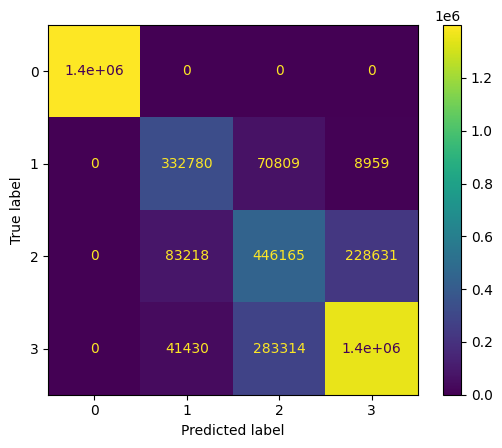

Class PR AUC: [[1.0, 0.8483388668254077, 0.5838735610420578, 0.9124034957684114]]
Mac PR AUC: ([np.float64(0.8361539809089693)])
1207
64
635
Started for fold 1
 Accuracy: 0.8297907708853142

 Confusion Matrix:
 [[1457282       0       0       0]
 [      0  345526   72244   10305]
 [      0   85205  449003  245367]
 [      0   44569  283634 1362234]]

Classification Report:
               precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   1457282
           1     0.7270    0.8072    0.7650    428075
           2     0.5579    0.5760    0.5668    779575
           3     0.8420    0.8058    0.8235   1690437

    accuracy                         0.8298   4355369
   macro avg     0.7817    0.7972    0.7888   4355369
weighted avg     0.8327    0.8298    0.8309   4355369



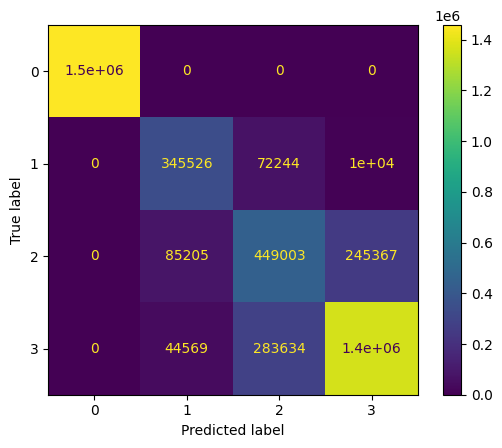

Class PR AUC: [[1.0, 0.8483388668254077, 0.5838735610420578, 0.9124034957684114], [1.0, 0.8474975012803367, 0.5815577172961209, 0.9074114893933812]]
Mac PR AUC: ([np.float64(0.8361539809089693), np.float64(0.8341166769924597)])
1207
64
635
Started for fold 2
 Accuracy: 0.8307810098263579

 Confusion Matrix:
 [[1398521       0       0       0]
 [      0  340276   71107    9223]
 [      0   83218  447359  238449]
 [      0   43325  279834 1373999]]

Classification Report:
               precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   1398521
           1     0.7289    0.8090    0.7669    420606
           2     0.5604    0.5817    0.5709    769026
           3     0.8473    0.8096    0.8280   1697158

    accuracy                         0.8308   4285311
   macro avg     0.7841    0.8001    0.7914   4285311
weighted avg     0.8340    0.8308    0.8320   4285311



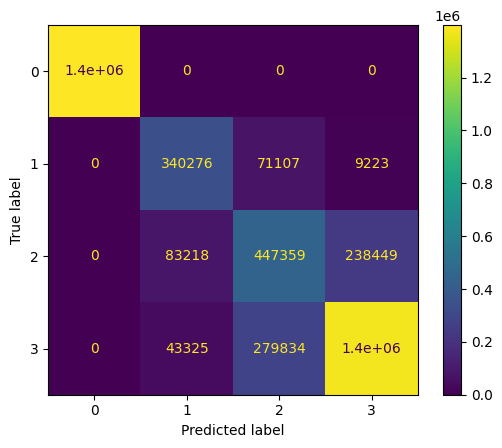

Class PR AUC: [[1.0, 0.8483388668254077, 0.5838735610420578, 0.9124034957684114], [1.0, 0.8474975012803367, 0.5815577172961209, 0.9074114893933812], [1.0, 0.8502554533390609, 0.5836956870796549, 0.9105097175383776]]
Mac PR AUC: ([np.float64(0.8361539809089693), np.float64(0.8341166769924597), np.float64(0.8361152144892734)])


/Users/beyzacinar/Desktop/HypoClass/Ensemble_Hypoglycemia_Classification/.venv/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/beyzacinar/Desktop/HypoClass/Ensemble_Hypoglycemia_Classification/.venv/lib/python3.11/site-packages/numpy/_core/_methods.py:144: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/Users/beyzacinar/Desktop/HypoClass/Ensemble_Hypoglycemia_Classification/.venv/lib/python3.11/site-packages/numpy/_core/_methods.py:222: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/Users/beyzacinar/Desktop/HypoClass/Ensemble_Hypoglycemia_Classification/.venv/lib/python3.11/site-packages/numpy/_core/_methods.py:180: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
/Users/beyzacinar/Desktop/HypoClass/Ensemble_Hyp

In [80]:
seed_value= 42  
os.environ["PYTHONHASHSEED"]=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)

from joblib import dump, load
from sklearn.utils import shuffle
import xgboost as xgb
from sklearn.metrics import (
accuracy_score,
classification_report,
confusion_matrix)
from sklearn.utils.class_weight import compute_class_weight
import joblib


best_params_rf = {'max_depth': 34, 'min_samples_split': 7, 'min_samples_leaf': 7, 'max_features': 0.5, 'bootstrap': True, 'n_estimators': 900}


# initializes 5 folds for cross validation
kfolds = KFold(n_splits=3, shuffle=False)#, random_state=42)

count = 0

# empty list for the predicted and actual values
y_true_labels = []
predicted_labels = []
predicted_prob_labels = []

# empty lists for the metrics calculated at each fold
lower_CI = []
upper_CI = []
F1_macro = []
Rec_macro = []
Pre_macro = []
PR_AUC_macro = []

F1_class = []
Rec_class = []
Pre_class = []
PR_AUC_class = []
PR_AVG_class = []
PR_AUC_Mac = []
PR_AVG_Mac = []


for train_idx, test_idx in kfolds.split(X_train_data):

    # split into temp and test (20%)
    train_idx, val_idx = train_test_split(train_idx, test_size=0.05, shuffle=False, random_state=seed_value)
    print(len(train_idx))
    print(len(val_idx))
    print(len(test_idx))

    average_precisions = []
    PRauc_scores = []

    print(f"Started for fold {count}")

    # extracts the selected subjects for training for the X and Y folds
    X_train_fold = [X_train_data[i] for i in train_idx]
    Y_train_fold = [Y_train_data[i] for i in train_idx]

    # flattens the arrays of single subjects into one array of shape (X,25,2)
    X_train_fold  =flatten(X_train_fold)
    # flattens the arrays of single subjects into one array of shape (X,1)
    Y_train_fold  =flatten(Y_train_fold)
    Y_train_fold  = Y_train_fold.reshape(-1)


    # extracts the selected subjects for validating for the X and Y folds
    X_val_fold = [X_train_data[i] for i in val_idx]
    Y_val_fold = [Y_train_data[i] for i in val_idx]

    # flattens the arrays of single subjects into one array of shape (X,25,2)
    X_val_fold =flatten(X_val_fold)
    # flattens the arrays of single subjects into one array of shape (X,1)
    Y_val_fold =flatten(Y_val_fold)
    Y_val_fold = Y_val_fold.reshape(-1)

    # extracts the selected subjects for testing for the X and Y folds
    X_test_fold = [X_train_data[i] for i in test_idx]
    Y_test_fold = [Y_train_data[i] for i in test_idx]

    # flattens the arrays of single subjects into one array of shape (X,25,2)
    X_test_fold =flatten(X_test_fold)
    # flattens the arrays of single subjects into one array of shape (X,1)
    Y_test_fold =flatten(Y_test_fold)
    Y_test_fold = Y_test_fold.reshape(-1)


    num_classes=len(np.unique(Y_train_fold))

    classes = np.unique(Y_train_fold)
    weights = compute_class_weight(class_weight="balanced", classes=classes, y=Y_train_fold)
    class_weight_dict = {int(k): float(v) for k, v in zip(classes, weights)}

    model_rf = RandomForestClassifier(
        **best_params_rf,
        class_weight=class_weight_dict,
        n_jobs=6,
        random_state=42,  verbose=0,# keep only one source of random_state
    )

    model_rf.fit(X_train_fold, Y_train_fold)


    y_pred_labels = model_rf.predict(X_test_fold)
    y_pred_prob = model_rf.predict_proba(X_test_fold)

    y_true_labels.append(Y_test_fold)  
    predicted_prob_labels.append(y_pred_prob) 
    predicted_labels.append(y_pred_labels)
    
    # === Step 8: Evaluation Metrics ===
    print(" Accuracy:", accuracy_score(Y_test_fold, y_pred_labels))
    print("\n Confusion Matrix:\n", confusion_matrix(Y_test_fold, y_pred_labels))
    print("\nClassification Report:\n", classification_report(Y_test_fold, y_pred_labels, digits=4))

    ConfusionMatrixDisplay.from_predictions(
        Y_test_fold, y_pred_labels)
    plt.show()


    f1_score_mac = f1_score(Y_test_fold, y_pred_labels, average='macro')
    F1_macro.append(f1_score_mac)

    rec_scores_mac = recall_score(Y_test_fold, y_pred_labels, average='macro')
    Rec_macro.append(rec_scores_mac)

    pre_scores_mac = precision_score(Y_test_fold, y_pred_labels, average='macro')
    Pre_macro.append(pre_scores_mac)

    f1_scores = f1_score(Y_test_fold, y_pred_labels, average=None, labels=np.arange(4))
    F1_class.append(f1_scores)

    rec_scores = recall_score(Y_test_fold, y_pred_labels, average=None, labels=np.arange(4))
    Rec_class.append(rec_scores)

    pre_scores = precision_score(Y_test_fold, y_pred_labels, average=None, labels=np.arange(4))
    Pre_class.append(pre_scores)

    Y_test_rs = to_categorical(Y_test_fold)
    classes = set(Y_test_fold)
    for n_cl, cl in enumerate(classes):  
            f_pre, f_rec, t = precision_recall_curve(Y_test_rs[:, cl], y_pred_prob[:, cl])
            sorted_indices = np.argsort(f_rec)
            pr_auc_scores = auc(f_rec, f_pre)
            ap_score = average_precision_score(Y_test_rs[:, cl], y_pred_prob[:, cl])
            average_precisions.append(ap_score)
            PRauc_scores.append(pr_auc_scores)

    PR_AVG_class.append(average_precisions)
    PR_AVG_scores_mac = np.mean(average_precisions)


    PR_AUC_class.append(PRauc_scores)
    PRAUC_mean = np.mean(PRauc_scores)
    PR_AUC_Mac.append(PRAUC_mean)

    print(f"Class PR AUC: {PR_AUC_class}")
    print(f"Mac PR AUC: ({PR_AUC_Mac})")

    count = count + 1

    

#    Saves reports of all folds and macro averages into txt file
with open("RF_5Fold.txt", "w") as f:

    f.write("Macro F1 Measure:")
    f.write(", ".join([f"{score:.4f}" for score in F1_macro]) + "\n")
    f.write(f"Mean Macro F1 Measure: {np.mean(F1_macro):.4f}" +"\n")
    f.write(f"STD Macro F1 Measure: {np.std(F1_macro):.4f}" +"\n\n")

    f.write("Macro Recall:")
    f.write(", ".join([f"{score:.4f}" for score in Rec_macro]) + "\n")
    f.write(f"Mean Macro Recall: {np.mean(Rec_macro):.4f}" +"\n")
    f.write(f"STD Macro Recall: {np.std(Rec_macro):.4f}" +"\n\n")

    f.write("Macro Precision:")
    f.write(", ".join([f"{score:.4f}" for score in Pre_macro]) + "\n")
    f.write(f"Mean Macro Precision: {np.mean(Pre_macro):.4f}" +"\n")
    f.write(f"STD Macro Precision: {np.std(Pre_macro):.4f}" +"\n\n")

    f.write("Macro PR AUC:")
    f.write(", ".join([f"{score:.4f}" for score in PR_AUC_Mac]) + "\n")
    f.write(f"Mean Macro PR AUC: {np.mean(PR_AUC_Mac):.4f}" +"\n")
    f.write(f"STD Macro PR AUC: {np.std(PR_AUC_Mac):.4f}" +"\n\n")

    f.write("Macro AVG PR:")
    f.write(", ".join([f"{score:.4f}" for score in PR_AVG_Mac]) + "\n")
    f.write(f"Mean Macro AVG PR: {np.mean(PR_AVG_Mac):.4f}" +"\n")
    f.write(f"STD Macro AVG PR: {np.std(PR_AVG_Mac):.4f}" +"\n\n")

    f.write("F1 Measure per Class:")
    f.write(", ".join([f"{score}" for score in F1_class]) + "\n\n")
   
    f.write("Recall per Class:")
    f.write(", ".join([f"{score}" for score in Rec_class]) + "\n\n")

    f.write("Precision per Class:")
    f.write(", ".join([f"{score}" for score in Pre_class]) + "\n\n")

    f.write("PR AUC per Class:")
    f.write(", ".join([f"{score}" for score in PR_AUC_class]) + "\n\n")

    f.write("AVG PR per Class:")
    f.write(", ".join([f"{score}" for score in PR_AVG_class]) + "\n\n")



# Save (single file)
dump(y_true_labels, "Data/y_true_RF.joblib", compress=("zlib", 1))
dump(predicted_labels, "Data/y_pred_RF.joblib", compress=("zlib", 1))
dump(predicted_prob_labels, "Data/y_pred_prob_RF.joblib", compress=("zlib", 1))


np.save("Data/y_true_RF.npy", np.array(y_true_labels, dtype=object), allow_pickle=True)
np.save("Data/y_pred_RF.npy", np.array(predicted_labels, dtype=object), allow_pickle=True)
np.save("Data/y_pred_prob_RF.npy", np.array(predicted_prob_labels, dtype=object), allow_pickle=True)

In [ ]:
seed_value= 42  
os.environ["PYTHONHASHSEED"]=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)


best_params_rf = best_params_rf = {'max_depth': 34, 'min_samples_split': 7, 'min_samples_leaf': 7, 'max_features': 0.5, 'bootstrap': True, 'n_estimators': 900}


classes = np.unique(Y_train_fold)
weights = compute_class_weight(class_weight="balanced", classes=classes, y=Y_train_fold)
class_weight_dict = {int(k): float(v) for k, v in zip(classes, weights)}

rf = RandomForestClassifier(
    **best_params_rf,
    class_weight=class_weight_dict,
    n_jobs=6,
    random_state=42,  verbose=0,# keep only one source of random_state
)

rf.fit(X_train_fold, Y_train_fold)

# === Predict on Test Set ===
y_pred_labels = rf.predict(X_test_fold)
y_pred_prob = rf.predict_proba(X_test_fold)

#print("\nConfusion Matrix:\n", confusion_matrix(Y_test_all, y_pred_labels))
print("Accuracy:", accuracy_score(Y_test_fold, y_pred_labels))
print("\nClassification Report:\n", classification_report(Y_test_fold, y_pred_labels, digits=4))

ConfusionMatrixDisplay.from_predictions(Y_test_fold, y_pred_labels)
plt.show()

name_rf = "model_rf.pkl"
joblib.dump(rf, name_rf)

ValueError: Expected 2D array, got 1D array instead:
array=[3. 3. 3. ... 0. 0. 0.].
Reshape your data either using array.reshape(-1, 1) if your data has a single feature or array.reshape(1, -1) if it contains a single sample.

Accuracy: 0.8352104996327865

Classification Report:
               precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   1199210
           1     0.7353    0.8167    0.7739    340979
           2     0.5616    0.5931    0.5769    626318
           3     0.8513    0.8066    0.8283   1385922

    accuracy                         0.8352   3552429
   macro avg     0.7871    0.8041    0.7948   3552429
weighted avg     0.8393    0.8352    0.8367   3552429



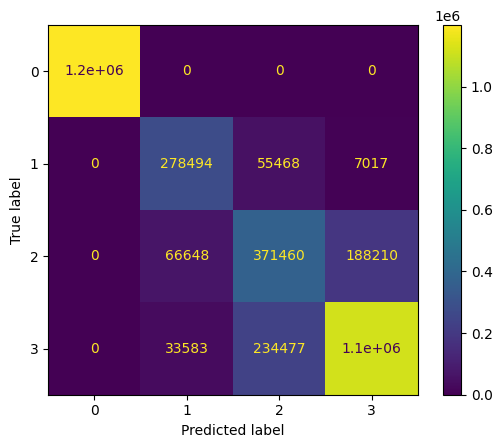

In [19]:
# === Predict on Test Set ===
y_pred_labels = rf.predict(X_test_fold)
y_pred_prob = rf.predict_proba(X_test_fold)

#print("\nConfusion Matrix:\n", confusion_matrix(Y_test_all, y_pred_labels))
print("Accuracy:", accuracy_score(Y_test_fold, y_pred_labels))
print("\nClassification Report:\n", classification_report(Y_test_fold, y_pred_labels, digits=4))

ConfusionMatrixDisplay.from_predictions(Y_test_fold, y_pred_labels)
plt.show()

In [18]:
name_rf = "model_rf.pkl"
joblib.dump(rf, name_rf)

['model_rf.pkl']

## CAT Boost

In [ ]:
import numpy as np
import optuna

from catboost import CatBoostClassifier, Pool
from sklearn.metrics import f1_score


# -----------------------------
# Sample weights for imbalance
# -----------------------------

def compute_sample_weight(y: np.ndarray) -> np.ndarray:
    classes, counts = np.unique(y, return_counts=True)
    freq = counts / counts.sum()
    w = {c: 1.0 / f for c, f in zip(classes, freq)}
    # normalize weights (optional)
    mean_w = np.mean(list(w.values()))
    w = {c: (val / mean_w) for c, val in w.items()}
    return np.array([w[yi] for yi in y], dtype=float)


USE_SAMPLE_WEIGHT = True

train_w = compute_sample_weight(Y_abl_train_fold) if USE_SAMPLE_WEIGHT else None
#al_w = compute_sample_weight(Y_abl_val_fold) if USE_SAMPLE_WEIGHT else None

NUM_CLASS = len(np.unique(Y_abl_train_fold))


# -----------------------------
# CatBoost Pools
# -----------------------------
train_pool = Pool(
    X_abl_train_fold,
    Y_abl_train_fold,
    weight=train_w if USE_SAMPLE_WEIGHT else None
)

val_pool = Pool(
    X_abl_val_fold,
    Y_abl_val_fold,
    #weight=val_w if USE_SAMPLE_WEIGHT else None
)


# -----------------------------
# Optuna objective
# -----------------------------
def objective(trial: optuna.trial.Trial) -> float:
    grow_policy = trial.suggest_categorical(
        "grow_policy", ["SymmetricTree", "Depthwise"]
    )
    params = {
        
        "loss_function": "MultiClass",
        "eval_metric": "MultiClass",

        # model complexity
        "depth": trial.suggest_int("depth", 3, 8),
        "grow_policy": grow_policy,

        # learning
        "learning_rate": trial.suggest_float(
            "learning_rate", 0.01, 0.2, log=True
        ),

        # regularization
        "l2_leaf_reg": trial.suggest_float(
            "l2_leaf_reg", 1.0, 100.0, log=True
        ),

        # randomness
        "random_strength": trial.suggest_float(
            "random_strength", 0.1, 20.0, log=True
        ),
        "bagging_temperature": trial.suggest_float(
            "bagging_temperature", 0.0, 10.0
        ),


        # tree growth
        #"min_data_in_leaf": trial.suggest_int(
         #   "min_data_in_leaf", 1, 300, log=True
        #),

        # boosting rounds
        "iterations": 5000, 

        # early stopping
        "od_type": "Iter",
        "od_wait": 100,

        # performance / reproducibility
        "random_seed": 42,
        "verbose": False,
        "allow_writing_files": False,
    }

     # only valid for non-symmetric trees
    if grow_policy == "Depthwise":
        params["min_data_in_leaf"] = trial.suggest_int(
            "min_data_in_leaf", 50, 1000, log=True
        )

    model = CatBoostClassifier(**params)

    model.fit(
        train_pool,
        eval_set=val_pool,
        use_best_model=True,
        verbose=False
    )

    y_pred = model.predict(X_abl_val_fold)
    y_pred = np.asarray(y_pred).reshape(-1)

    return f1_score(Y_abl_val_fold, y_pred, average="macro")


# -----------------------------
# Run Optuna
# -----------------------------
study_cat = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42),
)

study_cat.optimize(
    objective,
    n_trials=25,
    show_progress_bar=True
)

print("Best score:", study_cat.best_value)
print("Best params:", study_cat.best_params)

[I 2026-05-01 01:53:51,463] A new study created in memory with name: no-name-d2b54b84-b4d1-481e-a68c-de45da79a0db
Best trial: 0. Best value: 0.78449:   4%|▍         | 1/25 [07:45<3:06:19, 465.83s/it]

[I 2026-05-01 02:01:37,295] Trial 0 finished with value: 0.7844904384928285 and parameters: {'grow_policy': 'Depthwise', 'depth': 7, 'learning_rate': 0.060099747183803134, 'l2_leaf_reg': 2.05133826308745, 'random_strength': 0.22853255256339203, 'bagging_temperature': 0.5808361216819946, 'min_data_in_leaf': 669}. Best is trial 0 with value: 0.7844904384928285.


Best trial: 0. Best value: 0.78449:   8%|▊         | 2/25 [15:30<2:58:15, 465.02s/it]

[I 2026-05-01 02:09:21,744] Trial 1 finished with value: 0.7803034695904814 and parameters: {'grow_policy': 'Depthwise', 'depth': 3, 'learning_rate': 0.1827602783178572, 'l2_leaf_reg': 46.22589001020831, 'random_strength': 0.30803400529839686, 'bagging_temperature': 1.8182496720710062, 'min_data_in_leaf': 86}. Best is trial 0 with value: 0.7844904384928285.


Best trial: 0. Best value: 0.78449:  12%|█▏        | 3/25 [41:50<5:57:13, 974.27s/it]

[I 2026-05-01 02:35:42,023] Trial 2 finished with value: 0.7820268370860493 and parameters: {'grow_policy': 'Depthwise', 'depth': 5, 'learning_rate': 0.023927528765580634, 'l2_leaf_reg': 16.73808578875213, 'random_strength': 0.20940138873937436, 'bagging_temperature': 2.9214464853521815, 'min_data_in_leaf': 149}. Best is trial 0 with value: 0.7844904384928285.


... (40 outputs left out)

Best trial: 0. Best value: 0.78449:  96%|█████████▌| 24/25 [7:27:03<23:04, 1384.75s/it]

[I 2026-05-01 09:20:54,600] Trial 23 finished with value: 0.7842071486061741 and parameters: {'grow_policy': 'Depthwise', 'depth': 8, 'learning_rate': 0.03735853403596077, 'l2_leaf_reg': 10.514611082050719, 'random_strength': 0.427473086564285, 'bagging_temperature': 0.737091027825117, 'min_data_in_leaf': 306}. Best is trial 0 with value: 0.7844904384928285.


Best trial: 0. Best value: 0.78449: 100%|██████████| 25/25 [7:33:33<00:00, 1088.55s/it]

[I 2026-05-01 09:27:25,325] Trial 24 finished with value: 0.784114069334087 and parameters: {'grow_policy': 'Depthwise', 'depth': 8, 'learning_rate': 0.09025365658643444, 'l2_leaf_reg': 20.833882807833756, 'random_strength': 0.3898954082124576, 'bagging_temperature': 0.0020649790295309556, 'min_data_in_leaf': 302}. Best is trial 0 with value: 0.7844904384928285.
Best score: 0.7844904384928285
Best params: {'grow_policy': 'Depthwise', 'depth': 7, 'learning_rate': 0.060099747183803134, 'l2_leaf_reg': 2.05133826308745, 'random_strength': 0.22853255256339203, 'bagging_temperature': 0.5808361216819946, 'min_data_in_leaf': 669}


In [81]:
# ensures reproducability
seed_value= 42  
os.environ['PYTHONHASHSEED']=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)

# assuming X_data and Y_data are lists (or arrays) where each entry corresponds to one subject
subject_indices = list(range(len(Y_train)))


# split into temp and test (20%)
train_idx, abl_idx = train_test_split(subject_indices, test_size=0.05, shuffle=True, random_state=seed_value)
# split into temp and test (20%)
"""train_idx, abl_idx = train_test_split(temp_idx, test_size=0.05, shuffle=False, random_state=seed_value) """

abl_train_idx, abl_val_idx = train_test_split(abl_idx, test_size=0.20, shuffle=True, random_state=seed_value) 


X_train_data = [X_feat_train[i] for i in train_idx]
X_abl_train_data = [X_feat_train[i] for i in abl_train_idx]
X_abl_val_data = [X_feat_train[i] for i in abl_val_idx]

Y_train_data = [Y_train[i] for i in train_idx]
Y_abl_train_data = [Y_train[i] for i in abl_train_idx]
Y_abl_val_data = [Y_train[i] for i in abl_val_idx]

print(len(train_idx))
print(len(abl_idx))
print(len(abl_train_idx))
print(len(abl_val_idx))
print(len(X_feat_test))

1906
101
80
21
502


1206
64
636
Started for fold 0
Class Weights: {np.int64(0): np.float64(0.7546397073735792), np.int64(1): np.float64(2.5475246932388576), np.int64(2): np.float64(1.395973554726817), np.int64(3): np.float64(0.6385775674139619)}
0:	learn: 1.2787144	test: 1.2745333	best: 1.2745333 (0)	total: 7.48s	remaining: 2h 4m 34s
100:	learn: 0.4524380	test: 0.4307479	best: 0.4307479 (100)	total: 9m 36s	remaining: 1h 25m 30s
200:	learn: 0.4455342	test: 0.4275306	best: 0.4275306 (200)	total: 19m 5s	remaining: 1h 15m 54s
300:	learn: 0.4421067	test: 0.4261321	best: 0.4261321 (300)	total: 28m 33s	remaining: 1h 6m 20s
400:	learn: 0.4395729	test: 0.4251458	best: 0.4251458 (400)	total: 37m 59s	remaining: 56m 44s
500:	learn: 0.4375702	test: 0.4244605	best: 0.4244605 (500)	total: 47m 23s	remaining: 47m 12s
600:	learn: 0.4359888	test: 0.4239466	best: 0.4239466 (600)	total: 56m 48s	remaining: 37m 42s
700:	learn: 0.4343373	test: 0.4234117	best: 0.4234101 (699)	total: 1h 6m 12s	remaining: 28m 14s
800:	learn: 0.4329

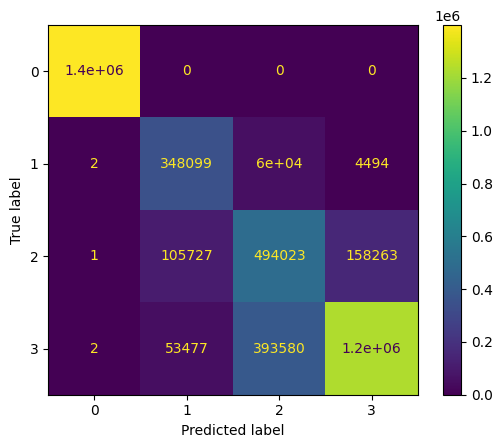

Class PR AUC: [[0.9999999149789001, 0.844776262586, 0.5668971862390535, 0.9144523004882289]]
Mac PR AUC: ([np.float64(0.8315314160730456)])
1207
64
635
Started for fold 1
Class Weights: {np.int64(0): np.float64(0.7610239929353285), np.int64(1): np.float64(2.5643566379917497), np.int64(2): np.float64(1.398667063155613), np.int64(3): np.float64(0.6324897897523422)}
0:	learn: 1.2783348	test: 1.2742570	best: 1.2742570 (0)	total: 6.78s	remaining: 1h 52m 55s
100:	learn: 0.4499231	test: 0.4303517	best: 0.4303517 (100)	total: 9m 28s	remaining: 1h 24m 17s
200:	learn: 0.4432065	test: 0.4274111	best: 0.4274111 (200)	total: 18m 50s	remaining: 1h 14m 54s
300:	learn: 0.4398839	test: 0.4261686	best: 0.4261686 (300)	total: 28m 11s	remaining: 1h 5m 27s
400:	learn: 0.4373912	test: 0.4252435	best: 0.4252384 (399)	total: 37m 28s	remaining: 55m 59s
500:	learn: 0.4356010	test: 0.4246393	best: 0.4246393 (500)	total: 46m 45s	remaining: 46m 34s
600:	learn: 0.4339209	test: 0.4240394	best: 0.4240394 (600)	total:

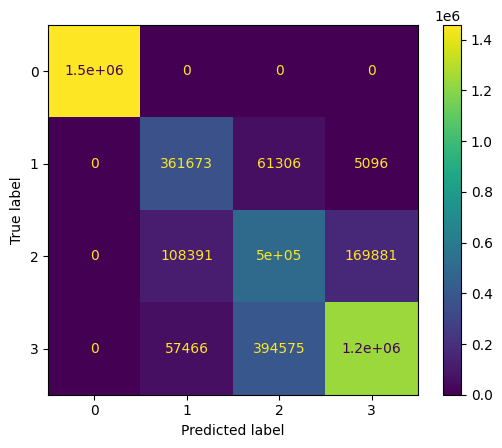

Class PR AUC: [[0.9999999149789001, 0.844776262586, 0.5668971862390535, 0.9144523004882289], [1.0, 0.84366760545076, 0.5667146580899473, 0.9095249118607517]]
Mac PR AUC: ([np.float64(0.8315314160730456), np.float64(0.8299767938503647)])
1207
64
635
Started for fold 2
Class Weights: {np.int64(0): np.float64(0.7515348276785373), np.int64(1): np.float64(2.5630107483721907), np.int64(2): np.float64(1.4005578030046513), np.int64(3): np.float64(0.6388868825902576)}
0:	learn: 1.2786977	test: 1.2731675	best: 1.2731675 (0)	total: 6.17s	remaining: 1h 42m 40s
100:	learn: 0.4533015	test: 0.4186666	best: 0.4186666 (100)	total: 9m 32s	remaining: 1h 24m 53s
200:	learn: 0.4466267	test: 0.4143816	best: 0.4143816 (200)	total: 18m 55s	remaining: 1h 15m 13s
300:	learn: 0.4431588	test: 0.4124409	best: 0.4124409 (300)	total: 28m 18s	remaining: 1h 5m 45s
400:	learn: 0.4408704	test: 0.4113320	best: 0.4113320 (400)	total: 37m 39s	remaining: 56m 15s
500:	learn: 0.4388585	test: 0.4103977	best: 0.4103977 (500)	to

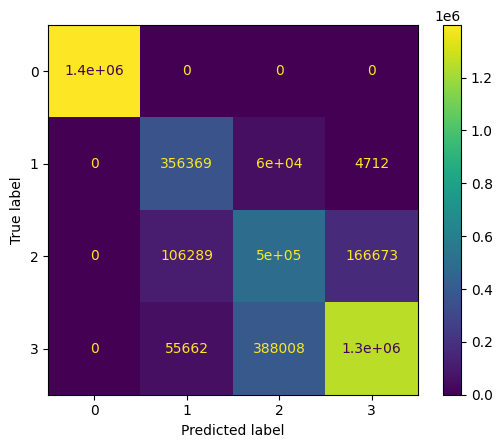

Class PR AUC: [[0.9999999149789001, 0.844776262586, 0.5668971862390535, 0.9144523004882289], [1.0, 0.84366760545076, 0.5667146580899473, 0.9095249118607517], [1.0, 0.8459811017080426, 0.5675050376627653, 0.9125865055673852]]
Mac PR AUC: ([np.float64(0.8315314160730456), np.float64(0.8299767938503647), np.float64(0.8315181612345484)])


/Users/beyzacinar/Desktop/HypoClass/Ensemble_Hypoglycemia_Classification/.venv/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/beyzacinar/Desktop/HypoClass/Ensemble_Hypoglycemia_Classification/.venv/lib/python3.11/site-packages/numpy/_core/_methods.py:144: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/Users/beyzacinar/Desktop/HypoClass/Ensemble_Hypoglycemia_Classification/.venv/lib/python3.11/site-packages/numpy/_core/_methods.py:222: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/Users/beyzacinar/Desktop/HypoClass/Ensemble_Hypoglycemia_Classification/.venv/lib/python3.11/site-packages/numpy/_core/_methods.py:180: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
/Users/beyzacinar/Desktop/HypoClass/Ensemble_Hyp

In [82]:
seed_value= 42  
os.environ["PYTHONHASHSEED"]=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)

from joblib import dump, load
from sklearn.utils import shuffle
import xgboost as xgb
from sklearn.metrics import (
accuracy_score,
classification_report,
confusion_matrix)
from sklearn.utils.class_weight import compute_class_weight
import joblib

best_params_cbc =  {'grow_policy': 'Depthwise', 'depth': 7, 'learning_rate': 0.060099747183803134, 'l2_leaf_reg': 2.05133826308745, 'random_strength': 0.22853255256339203, 'bagging_temperature': 0.5808361216819946, 'min_data_in_leaf': 669}


# initializes 5 folds for cross validation
kfolds = KFold(n_splits=3, shuffle=False)#, random_state=42)

count = 0

# empty list for the predicted and actual values
y_true_labels = []
predicted_labels = []
predicted_prob_labels = []

# empty lists for the metrics calculated at each fold
lower_CI = []
upper_CI = []
F1_macro = []
Rec_macro = []
Pre_macro = []
PR_AUC_macro = []

F1_class = []
Rec_class = []
Pre_class = []
PR_AUC_class = []
PR_AVG_class = []
PR_AUC_Mac = []
PR_AVG_Mac = []


for train_idx, test_idx in kfolds.split(X_train_data):

    # split into temp and test (20%)
    train_idx, val_idx = train_test_split(train_idx, test_size=0.05, shuffle=False, random_state=seed_value)
    print(len(train_idx))
    print(len(val_idx))
    print(len(test_idx))

    average_precisions = []
    PRauc_scores = []

    print(f"Started for fold {count}")

    # extracts the selected subjects for training for the X and Y folds
    X_train_fold = [X_train_data[i] for i in train_idx]
    Y_train_fold = [Y_train_data[i] for i in train_idx]

    # flattens the arrays of single subjects into one array of shape (X,25,2)
    X_train_fold  =flatten(X_train_fold)
    # flattens the arrays of single subjects into one array of shape (X,1)
    Y_train_fold  =flatten(Y_train_fold)
    Y_train_fold  = Y_train_fold.reshape(-1)


    # extracts the selected subjects for validating for the X and Y folds
    X_val_fold = [X_train_data[i] for i in val_idx]
    Y_val_fold = [Y_train_data[i] for i in val_idx]

    # flattens the arrays of single subjects into one array of shape (X,25,2)
    X_val_fold =flatten(X_val_fold)
    # flattens the arrays of single subjects into one array of shape (X,1)
    Y_val_fold =flatten(Y_val_fold)
    Y_val_fold = Y_val_fold.reshape(-1)

    # extracts the selected subjects for testing for the X and Y folds
    X_test_fold = [X_train_data[i] for i in test_idx]
    Y_test_fold = [Y_train_data[i] for i in test_idx]

    # flattens the arrays of single subjects into one array of shape (X,25,2)
    X_test_fold =flatten(X_test_fold)
    # flattens the arrays of single subjects into one array of shape (X,1)
    Y_test_fold =flatten(Y_test_fold)
    Y_test_fold = Y_test_fold.reshape(-1)

    num_classes=len(np.unique(Y_train_fold))


    model_cbc = CatBoostClassifier(**best_params_cbc, iterations=1000, loss_function="MultiClass",  
    eval_metric="MultiClass", random_seed=42, early_stopping_rounds=100, verbose = 100, 
    use_best_model=True, thread_count=-1)#,  eval_metric="mlogloss")
            
    #computes weights only on training labels
    classes = np.unique(Y_train_fold)
    weights = compute_class_weight('balanced', classes=classes, y=Y_train_fold)
    print("Class Weights:", dict(zip(classes, weights)))
    # assigns sample weights for training data
    sample_weights_train = np.array([weights[i] for i in Y_train_fold])

    train_pool = Pool(
    X_train_fold,
    Y_train_fold,
    weight=sample_weights_train
    )

    val_pool = Pool(
    X_val_fold,
    Y_val_fold
    )

    model_cbc.fit(
        train_pool,
        eval_set=val_pool,
        use_best_model=True,
        verbose=100
)          

    
    print(f"Early stopping best iteration: {model_cbc.get_best_iteration()}")
    # === Predict on Test Set ===
    y_pred_labels = model_cbc.predict(X_test_fold).reshape(-1)
    y_pred_prob = model_cbc.predict_proba(X_test_fold)


    y_true_labels.append(Y_test_fold)  
    predicted_prob_labels.append(y_pred_prob) 
    predicted_labels.append(y_pred_labels)
    
    # === Step 8: Evaluation Metrics ===
    print(" Accuracy:", accuracy_score(Y_test_fold, y_pred_labels))
    print("\n Confusion Matrix:\n", confusion_matrix(Y_test_fold, y_pred_labels))
    print("\nClassification Report:\n", classification_report(Y_test_fold, y_pred_labels, digits=4))

    ConfusionMatrixDisplay.from_predictions(
        Y_test_fold, y_pred_labels)
    plt.show()



    f1_score_mac = f1_score(Y_test_fold, y_pred_labels, average='macro')
    F1_macro.append(f1_score_mac)

    rec_scores_mac = recall_score(Y_test_fold, y_pred_labels, average='macro')
    Rec_macro.append(rec_scores_mac)

    pre_scores_mac = precision_score(Y_test_fold, y_pred_labels, average='macro')
    Pre_macro.append(pre_scores_mac)

    f1_scores = f1_score(Y_test_fold, y_pred_labels, average=None, labels=np.arange(4))
    F1_class.append(f1_scores)

    rec_scores = recall_score(Y_test_fold, y_pred_labels, average=None, labels=np.arange(4))
    Rec_class.append(rec_scores)

    pre_scores = precision_score(Y_test_fold, y_pred_labels, average=None, labels=np.arange(4))
    Pre_class.append(pre_scores)

    Y_test_rs = to_categorical(Y_test_fold)



    classes = set(Y_test_fold)

    for n_cl, cl in enumerate(classes):  
            f_pre, f_rec, t = precision_recall_curve(Y_test_rs[:, cl], y_pred_prob[:, cl])
            sorted_indices = np.argsort(f_rec)
            pr_auc_scores = auc(f_rec, f_pre)
            ap_score = average_precision_score(Y_test_rs[:, cl], y_pred_prob[:, cl])
            average_precisions.append(ap_score)
            PRauc_scores.append(pr_auc_scores)

    PR_AVG_class.append(average_precisions)
    PR_AVG_scores_mac = np.mean(average_precisions)


    PR_AUC_class.append(PRauc_scores)
    PRAUC_mean = np.mean(PRauc_scores)
    PR_AUC_Mac.append(PRAUC_mean)

    print(f"Class PR AUC: {PR_AUC_class}")
    print(f"Mac PR AUC: ({PR_AUC_Mac})")

    count = count + 1

    

#    Saves reports of all folds and macro averages into txt file
with open("CBC_3Fold.txt", "w") as f:

    f.write("Macro F1 Measure:")
    f.write(", ".join([f"{score:.4f}" for score in F1_macro]) + "\n")
    f.write(f"Mean Macro F1 Measure: {np.mean(F1_macro):.4f}" +"\n")
    f.write(f"STD Macro F1 Measure: {np.std(F1_macro):.4f}" +"\n\n")

    f.write("Macro Recall:")
    f.write(", ".join([f"{score:.4f}" for score in Rec_macro]) + "\n")
    f.write(f"Mean Macro Recall: {np.mean(Rec_macro):.4f}" +"\n")
    f.write(f"STD Macro Recall: {np.std(Rec_macro):.4f}" +"\n\n")

    f.write("Macro Precision:")
    f.write(", ".join([f"{score:.4f}" for score in Pre_macro]) + "\n")
    f.write(f"Mean Macro Precision: {np.mean(Pre_macro):.4f}" +"\n")
    f.write(f"STD Macro Precision: {np.std(Pre_macro):.4f}" +"\n\n")

    f.write("Macro PR AUC:")
    f.write(", ".join([f"{score:.4f}" for score in PR_AUC_Mac]) + "\n")
    f.write(f"Mean Macro PR AUC: {np.mean(PR_AUC_Mac):.4f}" +"\n")
    f.write(f"STD Macro PR AUC: {np.std(PR_AUC_Mac):.4f}" +"\n\n")

    f.write("Macro AVG PR:")
    f.write(", ".join([f"{score:.4f}" for score in PR_AVG_Mac]) + "\n")
    f.write(f"Mean Macro AVG PR: {np.mean(PR_AVG_Mac):.4f}" +"\n")
    f.write(f"STD Macro AVG PR: {np.std(PR_AVG_Mac):.4f}" +"\n\n")

    f.write("F1 Measure per Class:")
    f.write(", ".join([f"{score}" for score in F1_class]) + "\n\n")
   
    f.write("Recall per Class:")
    f.write(", ".join([f"{score}" for score in Rec_class]) + "\n\n")

    f.write("Precision per Class:")
    f.write(", ".join([f"{score}" for score in Pre_class]) + "\n\n")

    f.write("PR AUC per Class:")
    f.write(", ".join([f"{score}" for score in PR_AUC_class]) + "\n\n")

    f.write("AVG PR per Class:")
    f.write(", ".join([f"{score}" for score in PR_AVG_class]) + "\n\n")



# Save (single file)
dump(y_true_labels, "Data/y_true_CBC.joblib", compress=("zlib", 1))
dump(predicted_labels, "Data/y_pred_CBC.joblib", compress=("zlib", 1))
dump(predicted_prob_labels, "Data/y_pred_prob_CBC.joblib", compress=("zlib", 1))


np.save("Data/y_true_CBC.npy", np.array(y_true_labels, dtype=object), allow_pickle=True)
np.save("Data/y_pred_CBC.npy", np.array(predicted_labels, dtype=object), allow_pickle=True)
np.save("Data/y_pred_prob_CBC.npy", np.array(predicted_prob_labels, dtype=object), allow_pickle=True)

## XGB

In [33]:
import numpy as np
import optuna
from xgboost import XGBClassifier
from sklearn.metrics import f1_score

# -----------------------------
# Sample weights for imbalance (multiclass)
# -----------------------------


def compute_sample_weight(y: np.ndarray) -> np.ndarray:
    classes, counts = np.unique(y, return_counts=True)
    freq = counts / counts.sum()
    w = {c: 1.0 / f for c, f in zip(classes, freq)}
    # normalize weights (optional)
    mean_w = np.mean(list(w.values()))
    w = {c: (val / mean_w) for c, val in w.items()}
    return np.array([w[yi] for yi in y], dtype=float)

USE_SAMPLE_WEIGHT = True
train_w = compute_sample_weight(Y_abl_train_fold) if USE_SAMPLE_WEIGHT else None
#val_w   = compute_sample_weight(Y_abl_val_fold)   if USE_SAMPLE_WEIGHT else None   

NUM_CLASS = len(np.unique(Y_abl_train_fold))


def objective(trial: optuna.trial.Trial) -> float:
    params = {
        "objective": "multi:softprob",
        "num_class": NUM_CLASS,
        "eval_metric": "mlogloss",

        # model complexity
        "max_depth": trial.suggest_int("max_depth", 3, 8),

        # learning
        "learning_rate": trial.suggest_float("learning_rate", 5e-3, 0.3, log=True),

        # sampling
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),

        # regularization / split control
        "min_child_weight": trial.suggest_float("min_child_weight", 1.0, 20.0, log=True),
        "gamma": trial.suggest_float("gamma", 0.0, 10.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 100.0, log=True),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10.0, log=True),

        # max boosting rounds (early stopping will stop earlier)
        "n_estimators": 5000,

        # performance
        "tree_method": "hist",  # use "gpu_hist" if you have a CUDA GPU
        "n_jobs": -1,
        "random_state": 42,
    }

    model = XGBClassifier(**params,early_stopping_rounds=100,)

    fit_kwargs = dict(
        X=X_abl_train_fold,
        y=Y_abl_train_fold,
        eval_set=[(X_abl_val_fold, Y_abl_val_fold)],
        verbose=False
        
    )

    if USE_SAMPLE_WEIGHT:
        fit_kwargs["sample_weight"] = train_w
        #fit_kwargs["sample_weight_eval_set"] = [val_w]

    model.fit(**fit_kwargs)

    y_pred = model.predict(X_abl_val_fold)
    return f1_score(Y_abl_val_fold, y_pred, average="macro")

# -----------------------------
# Run Optuna
# -----------------------------
study_xgb = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42),
)

study_xgb.optimize(objective, n_trials=25, show_progress_bar=True)

print("Best score:", study_xgb.best_value)
print("Best params:", study_xgb.best_params)

[I 2026-04-30 13:17:45,849] A new study created in memory with name: no-name-0425e0c7-4b5d-4987-81a8-337f525eb440
Best trial: 0. Best value: 0.782909:   4%|▍         | 1/25 [00:18<07:26, 18.59s/it]

[I 2026-04-30 13:18:04,438] Trial 0 finished with value: 0.7829094176561171 and parameters: {'max_depth': 5, 'learning_rate': 0.24517932047070642, 'subsample': 0.8659969709057025, 'colsample_bytree': 0.7993292420985183, 'min_child_weight': 1.5958237752949744, 'gamma': 1.5599452033620265, 'reg_lambda': 0.0019517224641449498, 'reg_alpha': 2.915443189153755}. Best is trial 0 with value: 0.7829094176561171.


Best trial: 1. Best value: 0.783222:   8%|▊         | 2/25 [01:00<12:20, 32.18s/it]

[I 2026-04-30 13:18:46,126] Trial 1 finished with value: 0.7832218156713806 and parameters: {'max_depth': 6, 'learning_rate': 0.09078835431980901, 'subsample': 0.5102922471479012, 'colsample_bytree': 0.9849549260809971, 'min_child_weight': 12.10689693600216, 'gamma': 2.1233911067827616, 'reg_lambda': 0.008111941985431923, 'reg_alpha': 0.00541524411940254}. Best is trial 1 with value: 0.7832218156713806.


Best trial: 1. Best value: 0.783222:  12%|█▏        | 3/25 [03:08<27:49, 75.91s/it]

[I 2026-04-30 13:20:54,071] Trial 2 finished with value: 0.7830227089773317 and parameters: {'max_depth': 4, 'learning_rate': 0.042861395747190736, 'subsample': 0.7159725093210578, 'colsample_bytree': 0.645614570099021, 'min_child_weight': 6.252287916406214, 'gamma': 1.3949386065204183, 'reg_lambda': 0.028888383623653185, 'reg_alpha': 0.029204338471814112}. Best is trial 1 with value: 0.7832218156713806.


... (40 outputs left out)

Best trial: 19. Best value: 0.785349:  96%|█████████▌| 24/25 [59:56<03:06, 186.42s/it]

[I 2026-04-30 14:17:42,037] Trial 23 finished with value: 0.7832905830897835 and parameters: {'max_depth': 6, 'learning_rate': 0.007365228131714141, 'subsample': 0.8312783427507173, 'colsample_bytree': 0.7349074171376352, 'min_child_weight': 2.7316589635273862, 'gamma': 5.7924103149660295, 'reg_lambda': 0.018486765186666, 'reg_alpha': 0.003047760417200076}. Best is trial 19 with value: 0.7853492091979711.


Best trial: 24. Best value: 0.785631: 100%|██████████| 25/25 [1:02:20<00:00, 149.60s/it]

[I 2026-04-30 14:20:05,902] Trial 24 finished with value: 0.7856311654377519 and parameters: {'max_depth': 8, 'learning_rate': 0.01734972569154021, 'subsample': 0.9026845846532702, 'colsample_bytree': 0.778036172802511, 'min_child_weight': 4.996294335858327, 'gamma': 2.1859799766752293, 'reg_lambda': 0.0032865694291260893, 'reg_alpha': 0.04357102002476983}. Best is trial 24 with value: 0.7856311654377519.
Best score: 0.7856311654377519
Best params: {'max_depth': 8, 'learning_rate': 0.01734972569154021, 'subsample': 0.9026845846532702, 'colsample_bytree': 0.778036172802511, 'min_child_weight': 4.996294335858327, 'gamma': 2.1859799766752293, 'reg_lambda': 0.0032865694291260893, 'reg_alpha': 0.04357102002476983}


In [68]:
# ensures reproducability
seed_value= 42  
os.environ['PYTHONHASHSEED']=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)

# assuming X_data and Y_data are lists (or arrays) where each entry corresponds to one subject
subject_indices = list(range(len(Y_train)))


# split into temp and test (20%)
train_idx, abl_idx = train_test_split(subject_indices, test_size=0.05, shuffle=True, random_state=seed_value)
# split into temp and test (20%)
"""train_idx, abl_idx = train_test_split(temp_idx, test_size=0.05, shuffle=False, random_state=seed_value) """

abl_train_idx, abl_val_idx = train_test_split(abl_idx, test_size=0.20, shuffle=True, random_state=seed_value) 


X_train_data = [X_feat_train[i] for i in train_idx]
X_abl_train_data = [X_feat_train[i] for i in abl_train_idx]
X_abl_val_data = [X_feat_train[i] for i in abl_val_idx]

Y_train_data = [Y_train[i] for i in train_idx]
Y_abl_train_data = [Y_train[i] for i in abl_train_idx]
Y_abl_val_data = [Y_train[i] for i in abl_val_idx]

print(len(train_idx))
print(len(abl_idx))
print(len(abl_train_idx))
print(len(abl_val_idx))
print(len(X_feat_test))

1906
101
80
21
502


1206
64
636
Started for fold 0
Class Weights: {np.int64(0): np.float64(0.7546397073735792), np.int64(1): np.float64(2.5475246932388576), np.int64(2): np.float64(1.395973554726817), np.int64(3): np.float64(0.6385775674139619)}
Early stopping best iteration: 999
 Accuracy: 0.8172946876041745

 Confusion Matrix:
 [[1399934       0       0       0]
 [      6  346208   61690    4644]
 [      0  104042  493995  159977]
 [      0   52064  394199 1233922]]

Classification Report:
               precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   1399934
           1     0.6892    0.8392    0.7569    412548
           2     0.5201    0.6517    0.5785    758014
           3     0.8823    0.7344    0.8016   1680185

    accuracy                         0.8173   4250681
   macro avg     0.7729    0.8063    0.7842   4250681
weighted avg     0.8377    0.8173    0.8228   4250681



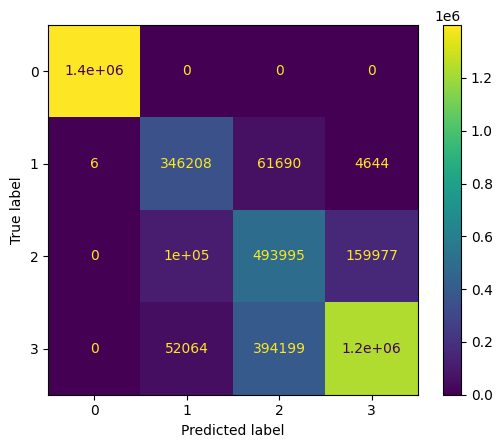

Class PR AUC: [[0.9999999997019621, 0.8432098174612053, 0.563073204163079, 0.9135548372750605]]
Mac PR AUC: ([np.float64(0.8299594646503267)])
1207
64
635
Started for fold 1
Class Weights: {np.int64(0): np.float64(0.7610239929353285), np.int64(1): np.float64(2.5643566379917497), np.int64(2): np.float64(1.398667063155613), np.int64(3): np.float64(0.6324897897523422)}
Early stopping best iteration: 999
 Accuracy: 0.8165186462961003

 Confusion Matrix:
 [[1457282       0       0       0]
 [      8  359736   63038    5293]
 [      0  107180  500643  171752]
 [      0   56411  395447 1238579]]

Classification Report:
               precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   1457282
           1     0.6874    0.8404    0.7562    428075
           2     0.5220    0.6422    0.5759    779575
           3     0.8749    0.7327    0.7975   1690437

    accuracy                         0.8165   4355369
   macro avg     0.7711    0.8038    0.7824   4355369

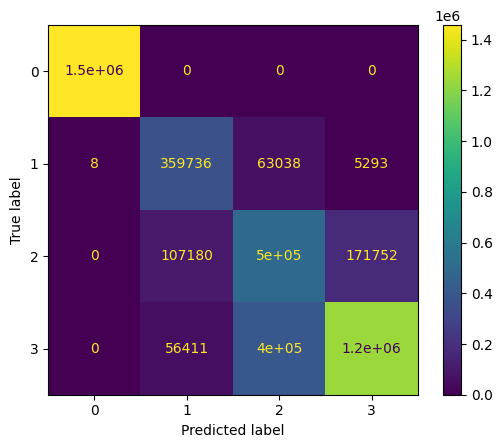

Class PR AUC: [[0.9999999997019621, 0.8432098174612053, 0.563073204163079, 0.9135548372750605], [0.9999999999284223, 0.8422110749606014, 0.5628507247567324, 0.9084849192103922]]
Mac PR AUC: ([np.float64(0.8299594646503267), np.float64(0.8283866797140371)])
1207
64
635
Started for fold 2
Class Weights: {np.int64(0): np.float64(0.7515348276785373), np.int64(1): np.float64(2.5630107483721907), np.int64(2): np.float64(1.4005578030046513), np.int64(3): np.float64(0.6388868825902576)}
Early stopping best iteration: 999
 Accuracy: 0.8172331016348638

 Confusion Matrix:
 [[1398521       0       0       0]
 [     16  354288   61374    4928]
 [      0  104793  496057  168176]
 [      0   54619  389307 1253232]]

Classification Report:
               precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   1398521
           1     0.6897    0.8423    0.7584    420606
           2     0.5240    0.6450    0.5782    769026
           3     0.8786    0.7384    0.8025   1

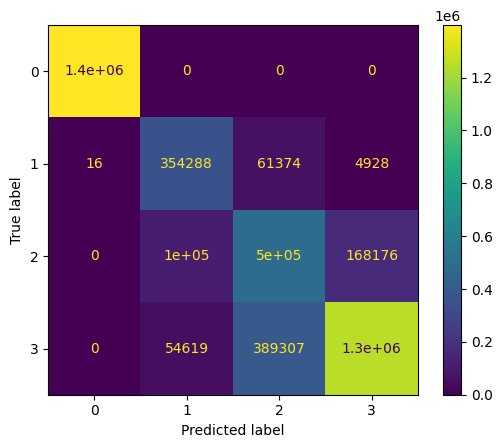

Class PR AUC: [[0.9999999997019621, 0.8432098174612053, 0.563073204163079, 0.9135548372750605], [0.9999999999284223, 0.8422110749606014, 0.5628507247567324, 0.9084849192103922], [0.9999999999923307, 0.8443427189083028, 0.563830702609054, 0.911651312488825]]
Mac PR AUC: ([np.float64(0.8299594646503267), np.float64(0.8283866797140371), np.float64(0.8299561834996281)])


/Users/beyzacinar/Desktop/HypoClass/Ensemble_Hypoglycemia_Classification/.venv/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/beyzacinar/Desktop/HypoClass/Ensemble_Hypoglycemia_Classification/.venv/lib/python3.11/site-packages/numpy/_core/_methods.py:144: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/Users/beyzacinar/Desktop/HypoClass/Ensemble_Hypoglycemia_Classification/.venv/lib/python3.11/site-packages/numpy/_core/_methods.py:222: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/Users/beyzacinar/Desktop/HypoClass/Ensemble_Hypoglycemia_Classification/.venv/lib/python3.11/site-packages/numpy/_core/_methods.py:180: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
/Users/beyzacinar/Desktop/HypoClass/Ensemble_Hyp

In [ ]:
seed_value= 42  
os.environ["PYTHONHASHSEED"]=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)

from joblib import dump, load
from sklearn.utils import shuffle
import xgboost as xgb
from sklearn.metrics import (
accuracy_score,
classification_report,
confusion_matrix)
from sklearn.utils.class_weight import compute_class_weight
import joblib

best_params_xgb = {'max_depth': 8, 'learning_rate': 0.01734972569154021, 'subsample': 0.9026845846532702, 'colsample_bytree': 0.778036172802511, 'min_child_weight': 4.996294335858327, 'gamma': 2.1859799766752293, 'reg_lambda': 0.0032865694291260893, 'reg_alpha': 0.04357102002476983, "n_estimators": 1000}


# initializes 5 folds for cross validation
kfolds = KFold(n_splits=3, shuffle=False)#, random_state=42)

count = 0

# empty list for the predicted and actual values
y_true_labels = []
predicted_labels = []
predicted_prob_labels = []

# empty lists for the metrics calculated at each fold
lower_CI = []
upper_CI = []
F1_macro = []
Rec_macro = []
Pre_macro = []
PR_AUC_macro = []

F1_class = []
Rec_class = []
Pre_class = []
PR_AUC_class = []
PR_AVG_class = []
PR_AUC_Mac = []
PR_AVG_Mac = []


for train_idx, test_idx in kfolds.split(X_train_data):

    # split into temp and test (20%)
    train_idx, val_idx = train_test_split(train_idx, test_size=0.05, shuffle=False, random_state=seed_value)
    print(len(train_idx))
    print(len(val_idx))
    print(len(test_idx))

    average_precisions = []
    PRauc_scores = []

    print(f"Started for fold {count}")

    # extracts the selected subjects for training for the X and Y folds
    X_train_fold = [X_train_data[i] for i in train_idx]
    Y_train_fold = [Y_train_data[i] for i in train_idx]

    # flattens the arrays of single subjects into one array of shape (X,25,2)
    X_train_fold  =flatten(X_train_fold)
    # flattens the arrays of single subjects into one array of shape (X,1)
    Y_train_fold  =flatten(Y_train_fold)
    Y_train_fold  = Y_train_fold.reshape(-1)


    # extracts the selected subjects for validating for the X and Y folds
    X_val_fold = [X_train_data[i] for i in val_idx]
    Y_val_fold = [Y_train_data[i] for i in val_idx]

    # flattens the arrays of single subjects into one array of shape (X,25,2)
    X_val_fold =flatten(X_val_fold)
    # flattens the arrays of single subjects into one array of shape (X,1)
    Y_val_fold =flatten(Y_val_fold)
    Y_val_fold = Y_val_fold.reshape(-1)

    # extracts the selected subjects for testing for the X and Y folds
    X_test_fold = [X_train_data[i] for i in test_idx]
    Y_test_fold = [Y_train_data[i] for i in test_idx]

    # flattens the arrays of single subjects into one array of shape (X,25,2)
    X_test_fold =flatten(X_test_fold)
    # flattens the arrays of single subjects into one array of shape (X,1)
    Y_test_fold =flatten(Y_test_fold)
    Y_test_fold = Y_test_fold.reshape(-1)


    xgb.set_config(verbosity=0) 

    num_classes=len(np.unique(Y_train_fold))
    model_xgb = xgb.XGBClassifier(**best_params_xgb, early_stopping_rounds=100, 
                                verbosity = 0, n_jobs=-1, objective="multi:softprob",
    num_class=num_classes,
    random_state=42,  eval_metric="mlogloss")
            
    #computes weights only on training labels
    classes = np.unique(Y_train_fold)
    weights = compute_class_weight('balanced', classes=classes, y=Y_train_fold)
    print("Class Weights:", dict(zip(classes, weights)))
    # assigns sample weights for training data
    sample_weights_train = np.array([weights[i] for i in Y_train_fold])

            

    model_xgb.fit(
        X_train_fold, Y_train_fold, 
        sample_weight=sample_weights_train,
        eval_set=[(X_val_fold, Y_val_fold)],
        verbose=False,
        
        #verbose=True,
        
        )
    print(f"Early stopping best iteration: {model_xgb.best_iteration}")
    # === Predict on Test Set ===
    y_pred_labels = model_xgb.predict(X_test_fold)
    y_pred_prob = model_xgb.predict_proba(X_test_fold)

    y_true_labels.append(Y_test_fold)  
    predicted_prob_labels.append(y_pred_prob) 
    predicted_labels.append(y_pred_labels)
    
    # === Step 8: Evaluation Metrics ===
    print(" Accuracy:", accuracy_score(Y_test_fold, y_pred_labels))
    print("\n Confusion Matrix:\n", confusion_matrix(Y_test_fold, y_pred_labels))
    print("\nClassification Report:\n", classification_report(Y_test_fold, y_pred_labels, digits=4))

    ConfusionMatrixDisplay.from_predictions(
        Y_test_fold, y_pred_labels)
    plt.show()


    f1_score_mac = f1_score(Y_test_fold, y_pred_labels, average='macro')
    F1_macro.append(f1_score_mac)

    rec_scores_mac = recall_score(Y_test_fold, y_pred_labels, average='macro')
    Rec_macro.append(rec_scores_mac)

    pre_scores_mac = precision_score(Y_test_fold, y_pred_labels, average='macro')
    Pre_macro.append(pre_scores_mac)

    f1_scores = f1_score(Y_test_fold, y_pred_labels, average=None, labels=np.arange(4))
    F1_class.append(f1_scores)

    rec_scores = recall_score(Y_test_fold, y_pred_labels, average=None, labels=np.arange(4))
    Rec_class.append(rec_scores)

    pre_scores = precision_score(Y_test_fold, y_pred_labels, average=None, labels=np.arange(4))
    Pre_class.append(pre_scores)

    Y_test_rs = to_categorical(Y_test_fold)
    classes = set(Y_test_fold)
    for n_cl, cl in enumerate(classes):  
            f_pre, f_rec, t = precision_recall_curve(Y_test_rs[:, cl], y_pred_prob[:, cl])
            sorted_indices = np.argsort(f_rec)
            pr_auc_scores = auc(f_rec, f_pre)
            ap_score = average_precision_score(Y_test_rs[:, cl], y_pred_prob[:, cl])
            average_precisions.append(ap_score)
            PRauc_scores.append(pr_auc_scores)

    PR_AVG_class.append(average_precisions)
    PR_AVG_scores_mac = np.mean(average_precisions)


    PR_AUC_class.append(PRauc_scores)
    PRAUC_mean = np.mean(PRauc_scores)
    PR_AUC_Mac.append(PRAUC_mean)

    print(f"Class PR AUC: {PR_AUC_class}")
    print(f"Mac PR AUC: ({PR_AUC_Mac})")

    count = count + 1

    

#    Saves reports of all folds and macro averages into txt file
with open("XGB_5Fold.txt", "w") as f:

    f.write("Macro F1 Measure:")
    f.write(", ".join([f"{score:.4f}" for score in F1_macro]) + "\n")
    f.write(f"Mean Macro F1 Measure: {np.mean(F1_macro):.4f}" +"\n")
    f.write(f"STD Macro F1 Measure: {np.std(F1_macro):.4f}" +"\n\n")

    f.write("Macro Recall:")
    f.write(", ".join([f"{score:.4f}" for score in Rec_macro]) + "\n")
    f.write(f"Mean Macro Recall: {np.mean(Rec_macro):.4f}" +"\n")
    f.write(f"STD Macro Recall: {np.std(Rec_macro):.4f}" +"\n\n")

    f.write("Macro Precision:")
    f.write(", ".join([f"{score:.4f}" for score in Pre_macro]) + "\n")
    f.write(f"Mean Macro Precision: {np.mean(Pre_macro):.4f}" +"\n")
    f.write(f"STD Macro Precision: {np.std(Pre_macro):.4f}" +"\n\n")

    f.write("Macro PR AUC:")
    f.write(", ".join([f"{score:.4f}" for score in PR_AUC_Mac]) + "\n")
    f.write(f"Mean Macro PR AUC: {np.mean(PR_AUC_Mac):.4f}" +"\n")
    f.write(f"STD Macro PR AUC: {np.std(PR_AUC_Mac):.4f}" +"\n\n")

    f.write("Macro AVG PR:")
    f.write(", ".join([f"{score:.4f}" for score in PR_AVG_Mac]) + "\n")
    f.write(f"Mean Macro AVG PR: {np.mean(PR_AVG_Mac):.4f}" +"\n")
    f.write(f"STD Macro AVG PR: {np.std(PR_AVG_Mac):.4f}" +"\n\n")

    f.write("F1 Measure per Class:")
    f.write(", ".join([f"{score}" for score in F1_class]) + "\n\n")
   
    f.write("Recall per Class:")
    f.write(", ".join([f"{score}" for score in Rec_class]) + "\n\n")

    f.write("Precision per Class:")
    f.write(", ".join([f"{score}" for score in Pre_class]) + "\n\n")

    f.write("PR AUC per Class:")
    f.write(", ".join([f"{score}" for score in PR_AUC_class]) + "\n\n")

    f.write("AVG PR per Class:")
    f.write(", ".join([f"{score}" for score in PR_AVG_class]) + "\n\n")



# Save (single file)
dump(y_true_labels, "Data/y_true_XGB.joblib", compress=("zlib", 1))
dump(predicted_labels, "Data/y_pred_XGB.joblib", compress=("zlib", 1))
dump(predicted_prob_labels, "Data/y_pred_prob_XGB.joblib", compress=("zlib", 1))


np.save("Data/y_true_XGB.npy", np.array(y_true_labels, dtype=object), allow_pickle=True)
np.save("Data/y_pred_XGB.npy", np.array(predicted_labels, dtype=object), allow_pickle=True)
np.save("Data/y_pred_prob_XGB.npy", np.array(predicted_prob_labels, dtype=object), allow_pickle=True)

## LightGBM

In [47]:
# ensures reproducability
seed_value= 42  
os.environ['PYTHONHASHSEED']=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)


USE_CLASS_WEIGHT = True

classes = np.unique(Y_abl_train_fold)
NUM_CLASS = len(classes)

cw = compute_class_weight(class_weight="balanced", classes=classes, y=Y_abl_train_fold)
class_weight_dict = {c: float(w) for c, w in zip(classes, cw)}  

def objective(trial: optuna.trial.Trial) -> float:
    params = {
        "boosting_type": "gbdt",
        "objective": "multiclass",
        "num_class": NUM_CLASS,
        "learning_rate": trial.suggest_float("learning_rate", 5e-3, 0.3, log=True),
        "n_estimators": 5000,  
        "num_leaves": trial.suggest_int("num_leaves", 31, 1024, log=True),
        "max_depth": trial.suggest_int("max_depth", -1, 16),
        "min_child_samples": trial.suggest_int("min_child_samples", 10, 200),
        "min_split_gain": trial.suggest_float("min_split_gain", 0.0, 1.0),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "subsample_freq": trial.suggest_int("subsample_freq", 1, 10),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-8, 100.0, log=True),
        "random_state": 42,
        "n_jobs": -1,
        "verbosity": -1,
    }

    model = lgb.LGBMClassifier(
        **params,
        class_weight=(class_weight_dict if USE_CLASS_WEIGHT else None),
    )

    # Prune using smooth validation metric (multi_logloss)
    #pruning_cb = optuna.integration.LightGBMPruningCallback(trial, "multi_logloss")

    model.fit(
        X_abl_train_fold,
        Y_abl_train_fold,
        eval_set=[(X_abl_val_fold, Y_abl_val_fold)],
        eval_metric="multi_logloss",
        callbacks=[
            lgb.early_stopping(stopping_rounds=100, verbose=False),
            #pruning_cb,
        ],
    )

    # Macro-F1 is the optimization target (maximize)
    y_pred = model.predict(X_abl_val_fold)
    return f1_score(Y_abl_val_fold, y_pred, average="macro")

# -----------------------------
# Study
# -----------------------------
study_lgm = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42),
    #pruner=optuna.pruners.MedianPruner(
    #    n_startup_trials=5,
    #   n_warmup_steps=200,   # boosting iterations
    #    interval_steps=50
   # ),
)

 
study_lgm.optimize(objective, n_trials=25, show_progress_bar=True)

print("Best score:", study_lgm.best_value)
print("Best params:", study_lgm.best_params)

[I 2026-04-30 16:55:45,336] A new study created in memory with name: no-name-ab0c230d-1828-4770-ab31-5f7dcc25b10a
  0%|          | 0/25 [00:00<?, ?it/s]/Users/beyzacinar/Desktop/HypoClass/Ensemble_Hypoglycemia_Classification/.venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
Best trial: 0. Best value: 0.784709:   4%|▍         | 1/25 [04:07<1:39:09, 247.90s/it]

[I 2026-04-30 16:59:53,236] Trial 0 finished with value: 0.7847094554334391 and parameters: {'learning_rate': 0.023171758042400858, 'num_leaves': 862, 'max_depth': 12, 'min_child_samples': 124, 'min_split_gain': 0.15601864044243652, 'subsample': 0.662397808134481, 'subsample_freq': 1, 'colsample_bytree': 0.9464704583099741, 'reg_alpha': 0.002570603566117596, 'reg_lambda': 0.12042752972516813}. Best is trial 0 with value: 0.7847094554334391.


/Users/beyzacinar/Desktop/HypoClass/Ensemble_Hypoglycemia_Classification/.venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
Best trial: 1. Best value: 0.78695:   8%|▊         | 2/25 [21:59<4:40:48, 732.57s/it] 

[I 2026-04-30 17:17:45,067] Trial 1 finished with value: 0.7869501790535445 and parameters: {'learning_rate': 0.005439667429522981, 'num_leaves': 922, 'max_depth': 13, 'min_child_samples': 50, 'min_split_gain': 0.18182496720710062, 'subsample': 0.6733618039413735, 'subsample_freq': 4, 'colsample_bytree': 0.8099025726528951, 'reg_alpha': 7.71800699380605e-05, 'reg_lambda': 8.171304639059403e-06}. Best is trial 1 with value: 0.7869501790535445.


/Users/beyzacinar/Desktop/HypoClass/Ensemble_Hypoglycemia_Classification/.venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
Best trial: 1. Best value: 0.78695:  12%|█▏        | 3/25 [22:46<2:33:45, 419.33s/it]

[I 2026-04-30 17:18:31,648] Trial 2 finished with value: 0.7833904067817785 and parameters: {'learning_rate': 0.061226156060280326, 'num_leaves': 50, 'max_depth': 4, 'min_child_samples': 79, 'min_split_gain': 0.45606998421703593, 'subsample': 0.9140703845572055, 'subsample_freq': 2, 'colsample_bytree': 0.8056937753654446, 'reg_alpha': 0.0021465011216654484, 'reg_lambda': 2.9140978279786215e-08}. Best is trial 1 with value: 0.7869501790535445.


... (40 outputs left out)

/Users/beyzacinar/Desktop/HypoClass/Ensemble_Hypoglycemia_Classification/.venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
Best trial: 1. Best value: 0.78695:  96%|█████████▌| 24/25 [2:21:12<06:15, 375.39s/it]

[I 2026-04-30 19:16:57,632] Trial 23 finished with value: 0.7862087718860011 and parameters: {'learning_rate': 0.012882456986817042, 'num_leaves': 981, 'max_depth': 14, 'min_child_samples': 32, 'min_split_gain': 0.6960992848271103, 'subsample': 0.6432535618327889, 'subsample_freq': 5, 'colsample_bytree': 0.8828098807721825, 'reg_alpha': 1.36637557419345e-07, 'reg_lambda': 9.872641678260556e-08}. Best is trial 1 with value: 0.7869501790535445.


/Users/beyzacinar/Desktop/HypoClass/Ensemble_Hypoglycemia_Classification/.venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
Best trial: 1. Best value: 0.78695: 100%|██████████| 25/25 [2:36:07<00:00, 374.69s/it]

[I 2026-04-30 19:31:52,708] Trial 24 finished with value: 0.7853295237922802 and parameters: {'learning_rate': 0.006400895404529058, 'num_leaves': 310, 'max_depth': 16, 'min_child_samples': 101, 'min_split_gain': 0.5368054882950819, 'subsample': 0.7290284435127216, 'subsample_freq': 4, 'colsample_bytree': 0.7741686384095295, 'reg_alpha': 5.724132805555745e-06, 'reg_lambda': 0.003759901916242067}. Best is trial 1 with value: 0.7869501790535445.
Best score: 0.7869501790535445
Best params: {'learning_rate': 0.005439667429522981, 'num_leaves': 922, 'max_depth': 13, 'min_child_samples': 50, 'min_split_gain': 0.18182496720710062, 'subsample': 0.6733618039413735, 'subsample_freq': 4, 'colsample_bytree': 0.8099025726528951, 'reg_alpha': 7.71800699380605e-05, 'reg_lambda': 8.171304639059403e-06}


In [6]:
# ensures reproducability
seed_value= 42  
os.environ['PYTHONHASHSEED']=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)

# assuming X_data and Y_data are lists (or arrays) where each entry corresponds to one subject
subject_indices = list(range(len(Y_train)))


# split into temp and test (20%)
train_idx, abl_idx = train_test_split(subject_indices, test_size=0.05, shuffle=True, random_state=seed_value)
# split into temp and test (20%)
"""train_idx, abl_idx = train_test_split(temp_idx, test_size=0.05, shuffle=False, random_state=seed_value) """

abl_train_idx, abl_val_idx = train_test_split(abl_idx, test_size=0.20, shuffle=True, random_state=seed_value) 


X_train_data = [X_feat_train[i] for i in train_idx]
X_abl_train_data = [X_feat_train[i] for i in abl_train_idx]
X_abl_val_data = [X_feat_train[i] for i in abl_val_idx]

Y_train_data = [Y_train[i] for i in train_idx]
Y_abl_train_data = [Y_train[i] for i in abl_train_idx]
Y_abl_val_data = [Y_train[i] for i in abl_val_idx]

print(len(train_idx))
print(len(abl_idx))
print(len(abl_train_idx))
print(len(abl_val_idx))
print(len(X_feat_test))

1906
101
80
21
502


1206
64
636
Started for fold 0
Class Weights: {np.int64(0): np.float64(0.7546397073735792), np.int64(1): np.float64(2.5475246932388576), np.int64(2): np.float64(1.395973554726817), np.int64(3): np.float64(0.6385775674139619)}
min_split_gain: 0.18182496720710062
min_child_samples: 50
Training until validation scores don't improve for 100 rounds
[50]	valid_0's multi_logloss: 1.0051
[100]	valid_0's multi_logloss: 0.795664
[150]	valid_0's multi_logloss: 0.668975
[200]	valid_0's multi_logloss: 0.588898
[250]	valid_0's multi_logloss: 0.537053
[300]	valid_0's multi_logloss: 0.502738
[350]	valid_0's multi_logloss: 0.479585
[400]	valid_0's multi_logloss: 0.463671
[450]	valid_0's multi_logloss: 0.452565
[500]	valid_0's multi_logloss: 0.44465
[550]	valid_0's multi_logloss: 0.438876
[600]	valid_0's multi_logloss: 0.434631
[650]	valid_0's multi_logloss: 0.431432
[700]	valid_0's multi_logloss: 0.428984
[750]	valid_0's multi_logloss: 0.427113
[800]	valid_0's multi_logloss: 0.425611
[850]	valid_0's mu

/Users/beyzacinar/Desktop/HypoClass/Ensemble_Hypoglycemia_Classification/.venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/beyzacinar/Desktop/HypoClass/Ensemble_Hypoglycemia_Classification/.venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


 Accuracy: 0.8177804921140871

 Confusion Matrix:
 [[1399934       0       0       0]
 [      0  348277   59569    4702]
 [      0  105267  493396  159351]
 [      1   53273  392394 1234517]]

Classification Report:
               precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   1399934
           1     0.6872    0.8442    0.7576    412548
           2     0.5219    0.6509    0.5793    758014
           3     0.8827    0.7348    0.8020   1680185

    accuracy                         0.8178   4250681
   macro avg     0.7729    0.8075    0.7847   4250681
weighted avg     0.8380    0.8178    0.8232   4250681



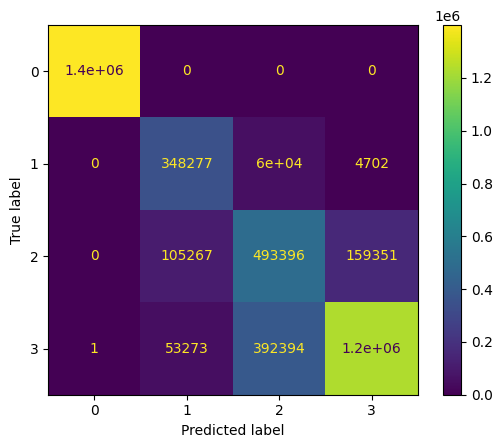

Class PR AUC: [[1.0, 0.8486020517759273, 0.5700252950802617, 0.9141135960765131]]
Mac PR AUC: ([np.float64(0.8331852357331755)])
1207
64
635
Started for fold 1
Class Weights: {np.int64(0): np.float64(0.7610239929353285), np.int64(1): np.float64(2.5643566379917497), np.int64(2): np.float64(1.398667063155613), np.int64(3): np.float64(0.6324897897523422)}
min_split_gain: 0.18182496720710062
min_child_samples: 50
Training until validation scores don't improve for 100 rounds
[50]	valid_0's multi_logloss: 1.00441
[100]	valid_0's multi_logloss: 0.79478
[150]	valid_0's multi_logloss: 0.668043
[200]	valid_0's multi_logloss: 0.587985
[250]	valid_0's multi_logloss: 0.536211
[300]	valid_0's multi_logloss: 0.501971
[350]	valid_0's multi_logloss: 0.478942
[400]	valid_0's multi_logloss: 0.463123
[450]	valid_0's multi_logloss: 0.452129
[500]	valid_0's multi_logloss: 0.444285
[550]	valid_0's multi_logloss: 0.438606
[600]	valid_0's multi_logloss: 0.434433
[650]	valid_0's multi_logloss: 0.431269
[700]	va

/Users/beyzacinar/Desktop/HypoClass/Ensemble_Hypoglycemia_Classification/.venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/beyzacinar/Desktop/HypoClass/Ensemble_Hypoglycemia_Classification/.venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


 Accuracy: 0.8171362747909534

 Confusion Matrix:
 [[1457282       0       0       0]
 [      0  361685   60991    5399]
 [      1  107847  500137  171590]
 [      1   57209  393401 1239826]]

Classification Report:
               precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   1457282
           1     0.6866    0.8449    0.7576    428075
           2     0.5240    0.6416    0.5768    779575
           3     0.8751    0.7334    0.7980   1690437

    accuracy                         0.8171   4355369
   macro avg     0.7714    0.8050    0.7831   4355369
weighted avg     0.8355    0.8171    0.8220   4355369



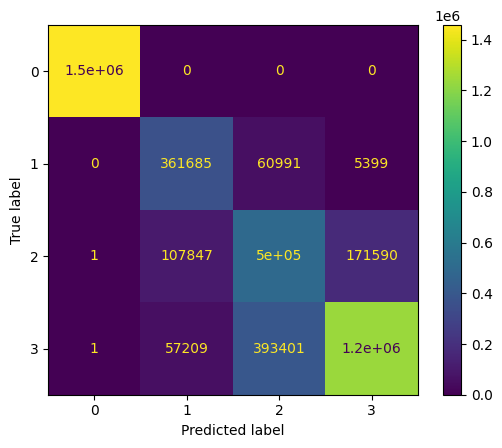

Class PR AUC: [[1.0, 0.8486020517759273, 0.5700252950802617, 0.9141135960765131], [1.0, 0.8481315935761142, 0.5699442192733, 0.9090312479027671]]
Mac PR AUC: ([np.float64(0.8331852357331755), np.float64(0.8317767651880454)])
1207
64
635
Started for fold 2
Class Weights: {np.int64(0): np.float64(0.7515348276785373), np.int64(1): np.float64(2.5630107483721907), np.int64(2): np.float64(1.4005578030046513), np.int64(3): np.float64(0.6388868825902576)}
min_split_gain: 0.18182496720710062
min_child_samples: 50
Training until validation scores don't improve for 100 rounds
[50]	valid_0's multi_logloss: 1.00024
[100]	valid_0's multi_logloss: 0.787948
[150]	valid_0's multi_logloss: 0.659369
[200]	valid_0's multi_logloss: 0.577952
[250]	valid_0's multi_logloss: 0.525189
[300]	valid_0's multi_logloss: 0.490213
[350]	valid_0's multi_logloss: 0.466609
[400]	valid_0's multi_logloss: 0.450367
[450]	valid_0's multi_logloss: 0.439054
[500]	valid_0's multi_logloss: 0.430981
[550]	valid_0's multi_logloss:

/Users/beyzacinar/Desktop/HypoClass/Ensemble_Hypoglycemia_Classification/.venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/beyzacinar/Desktop/HypoClass/Ensemble_Hypoglycemia_Classification/.venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


 Accuracy: 0.8179364344851517

 Confusion Matrix:
 [[1398521       0       0       0]
 [      1  356389   59330    4886]
 [      1  105524  495726  167775]
 [      0   55627  387055 1254476]]

Classification Report:
               precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   1398521
           1     0.6886    0.8473    0.7598    420606
           2     0.5262    0.6446    0.5794    769026
           3     0.8790    0.7392    0.8030   1697158

    accuracy                         0.8179   4285311
   macro avg     0.7735    0.8078    0.7856   4285311
weighted avg     0.8365    0.8179    0.8229   4285311



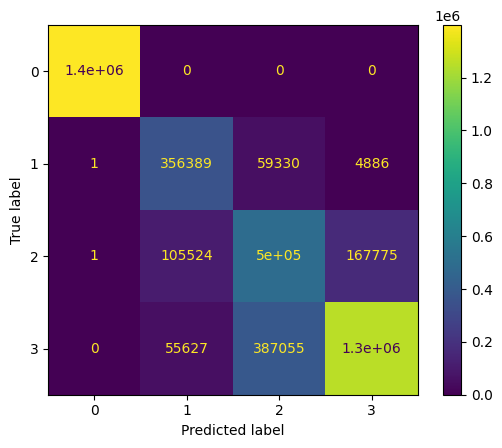

Class PR AUC: [[1.0, 0.8486020517759273, 0.5700252950802617, 0.9141135960765131], [1.0, 0.8481315935761142, 0.5699442192733, 0.9090312479027671], [1.0, 0.8502135433333946, 0.5712802467682588, 0.9122248501409302]]
Mac PR AUC: ([np.float64(0.8331852357331755), np.float64(0.8317767651880454), np.float64(0.8334296600606459)])


/Users/beyzacinar/Desktop/HypoClass/Ensemble_Hypoglycemia_Classification/.venv/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/beyzacinar/Desktop/HypoClass/Ensemble_Hypoglycemia_Classification/.venv/lib/python3.11/site-packages/numpy/_core/_methods.py:144: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/Users/beyzacinar/Desktop/HypoClass/Ensemble_Hypoglycemia_Classification/.venv/lib/python3.11/site-packages/numpy/_core/_methods.py:222: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/Users/beyzacinar/Desktop/HypoClass/Ensemble_Hypoglycemia_Classification/.venv/lib/python3.11/site-packages/numpy/_core/_methods.py:180: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
/Users/beyzacinar/Desktop/HypoClass/Ensemble_Hyp

NameError: name 'dump' is not defined

In [7]:
seed_value= 42  
os.environ["PYTHONHASHSEED"]=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)



best_params = {'learning_rate': 0.005439667429522981, 'num_leaves': 922, 'max_depth': 13, 'min_child_samples': 50, 'min_split_gain': 0.18182496720710062, 'subsample': 0.6733618039413735, 'subsample_freq': 4, 'colsample_bytree': 0.8099025726528951, 'reg_alpha': 7.71800699380605e-05, 'reg_lambda': 8.171304639059403e-06}
#study_lgm.best_params
#{'learning_rate': 0.014450146667310666, 'num_leaves': 1022, 'max_depth': 16, 'min_child_samples': 62, 'min_split_gain': 0.5396201068027975, 'subsample': 0.7483987646896224, 'subsample_freq': 5, 'colsample_bytree': 0.869545659576201, 'reg_alpha': 4.872969385182971e-07, 'reg_lambda': 1.1292203747250897e-08}
#{'learning_rate': 0.005439667429522981, 'num_leaves': 922, 'max_depth': 13, 'min_child_samples': 50, 'min_split_gain': 0.18182496720710062, 'subsample': 0.6733618039413735, 'subsample_freq': 4, 'colsample_bytree': 0.8099025726528951, 'reg_alpha': 7.71800699380605e-05, 'reg_lambda': 8.171304639059403e-06}


params_fixed = {
    **best_params,  
    "n_estimators": 1000,      
}

# initializes 5 folds for cross validation
kfolds = KFold(n_splits=3, shuffle=False)#, random_state=42)

count = 0

# empty list for the predicted and actual values
y_true_labels = []
predicted_labels = []
predicted_prob_labels = []

# empty lists for the metrics calculated at each fold
lower_CI = []
upper_CI = []
F1_macro = []
Rec_macro = []
Pre_macro = []
PR_AUC_macro = []

F1_class = []
Rec_class = []
Pre_class = []
PR_AUC_class = []
PR_AVG_class = []
PR_AUC_Mac = []
PR_AVG_Mac = []



for train_idx, test_idx in kfolds.split(X_train_data):

    # split into temp and test (20%)
    train_idx, val_idx = train_test_split(train_idx, test_size=0.05, shuffle=False, random_state=seed_value)
    print(len(train_idx))
    print(len(val_idx))
    print(len(test_idx))

    average_precisions = []
    PRauc_scores = []

    print(f"Started for fold {count}")

    # extracts the selected subjects for training for the X and Y folds
    X_train_fold = [X_train_data[i] for i in train_idx]
    Y_train_fold = [Y_train_data[i] for i in train_idx]

    # flattens the arrays of single subjects into one array of shape (X,25,2)
    X_train_fold  =flatten(X_train_fold)
    # flattens the arrays of single subjects into one array of shape (X,1)
    Y_train_fold  =flatten(Y_train_fold)
    Y_train_fold  = Y_train_fold.reshape(-1)


    # extracts the selected subjects for validating for the X and Y folds
    X_val_fold = [X_train_data[i] for i in val_idx]
    Y_val_fold = [Y_train_data[i] for i in val_idx]

    # flattens the arrays of single subjects into one array of shape (X,25,2)
    X_val_fold =flatten(X_val_fold)
    # flattens the arrays of single subjects into one array of shape (X,1)
    Y_val_fold =flatten(Y_val_fold)
    Y_val_fold = Y_val_fold.reshape(-1)

    # extracts the selected subjects for testing for the X and Y folds
    X_test_fold = [X_train_data[i] for i in test_idx]
    Y_test_fold = [Y_train_data[i] for i in test_idx]

    # flattens the arrays of single subjects into one array of shape (X,25,2)
    X_test_fold =flatten(X_test_fold)
    # flattens the arrays of single subjects into one array of shape (X,1)
    Y_test_fold =flatten(Y_test_fold)
    Y_test_fold = Y_test_fold.reshape(-1)


    #computes weights only on training labels
    classes = np.unique(Y_train_fold)
    weights = compute_class_weight('balanced', classes=classes, y=Y_train_fold)
    print("Class Weights:", dict(zip(classes, weights)))
    # assigns sample weights for training data
    sample_weights_train = np.array([weights[i] for i in Y_train_fold])

            
    lgm_model = lgb.LGBMClassifier(
        **params_fixed,
        objective="multiclass",
        num_class=4,
        n_jobs=-1,
        random_state=42,
        verbosity=-1,
    )

    print("min_split_gain:", lgm_model.get_params()["min_split_gain"])
    print("min_child_samples:", lgm_model.get_params()["min_child_samples"])


    lgm_model.fit(
        X_train_fold, Y_train_fold,
        sample_weight=sample_weights_train,
        eval_set=[(X_val_fold, Y_val_fold)],
        eval_metric="multi_logloss",
        callbacks=[lgb.early_stopping(stopping_rounds=100),lgb.log_evaluation(50)
        ],
    )
    print(f"Early stopping at iteration: {lgm_model.best_iteration_}")

    # === Step 7: Predict on Test Set ===
    y_pred_labels = lgm_model.predict(X_test_fold)
    
    y_pred_prob = lgm_model.predict_proba(X_test_fold)


    # === Step 8: Evaluation Metrics ===
    print(" Accuracy:", accuracy_score(Y_test_fold, y_pred_labels))
    print("\n Confusion Matrix:\n", confusion_matrix(Y_test_fold, y_pred_labels))
    print("\nClassification Report:\n", classification_report(Y_test_fold, y_pred_labels, digits=4))

    ConfusionMatrixDisplay.from_predictions(
        Y_test_fold, y_pred_labels)
    plt.show()


    y_true_labels.append(Y_test_fold)  
    predicted_labels.append(y_pred_labels) 
    predicted_prob_labels.append(y_pred_prob) 

    f1_score_mac = f1_score(Y_test_fold, y_pred_labels, average='macro')
    F1_macro.append(f1_score_mac)

    rec_scores_mac = recall_score(Y_test_fold, y_pred_labels, average='macro')
    Rec_macro.append(rec_scores_mac)

    pre_scores_mac = precision_score(Y_test_fold, y_pred_labels, average='macro')
    Pre_macro.append(pre_scores_mac)

    f1_scores = f1_score(Y_test_fold, y_pred_labels, average=None, labels=np.arange(4))
    F1_class.append(f1_scores)

    rec_scores = recall_score(Y_test_fold, y_pred_labels, average=None, labels=np.arange(4))
    Rec_class.append(rec_scores)

    pre_scores = precision_score(Y_test_fold, y_pred_labels, average=None, labels=np.arange(4))
    Pre_class.append(pre_scores)

    Y_test_rs = to_categorical(Y_test_fold)
    classes = set(Y_test_fold)
    for n_cl, cl in enumerate(classes):  
            f_pre, f_rec, t = precision_recall_curve(Y_test_rs[:, cl], y_pred_prob[:, cl])
            sorted_indices = np.argsort(f_rec)
            pr_auc_scores = auc(f_rec, f_pre)
            ap_score = average_precision_score(Y_test_rs[:, cl], y_pred_prob[:, cl])
            average_precisions.append(ap_score)
            PRauc_scores.append(pr_auc_scores)

    PR_AVG_class.append(average_precisions)
    PR_AVG_scores_mac = np.mean(average_precisions)


    PR_AUC_class.append(PRauc_scores)
    PRAUC_mean = np.mean(PRauc_scores)
    PR_AUC_Mac.append(PRAUC_mean)

    print(f"Class PR AUC: {PR_AUC_class}")
    print(f"Mac PR AUC: ({PR_AUC_Mac})")

    count = count + 1

    


    

# Saves reports of all folds and macro averages into txt file
with open("LighBGM_3Fold.txt", "w") as f:

    f.write("Macro F1 Measure:")
    f.write(", ".join([f"{score:.4f}" for score in F1_macro]) + "\n")
    f.write(f"Mean Macro F1 Measure: {np.mean(F1_macro):.4f}" +"\n")
    f.write(f"STD Macro F1 Measure: {np.std(F1_macro):.4f}" +"\n\n")

    f.write("Macro Recall:")
    f.write(", ".join([f"{score:.4f}" for score in Rec_macro]) + "\n")
    f.write(f"Mean Macro Recall: {np.mean(Rec_macro):.4f}" +"\n")
    f.write(f"STD Macro Recall: {np.std(Rec_macro):.4f}" +"\n\n")

    f.write("Macro Precision:")
    f.write(", ".join([f"{score:.4f}" for score in Pre_macro]) + "\n")
    f.write(f"Mean Macro Precision: {np.mean(Pre_macro):.4f}" +"\n")
    f.write(f"STD Macro Precision: {np.std(Pre_macro):.4f}" +"\n\n")

    f.write("Macro PR AUC:")
    f.write(", ".join([f"{score:.4f}" for score in PR_AUC_Mac]) + "\n")
    f.write(f"Mean Macro PR AUC: {np.mean(PR_AUC_Mac):.4f}" +"\n")
    f.write(f"STD Macro PR AUC: {np.std(PR_AUC_Mac):.4f}" +"\n\n")

    f.write("Macro AVG PR:")
    f.write(", ".join([f"{score:.4f}" for score in PR_AVG_Mac]) + "\n")
    f.write(f"Mean Macro AVG PR: {np.mean(PR_AVG_Mac):.4f}" +"\n")
    f.write(f"STD Macro AVG PR: {np.std(PR_AVG_Mac):.4f}" +"\n\n")

    f.write("F1 Measure per Class:")
    f.write(", ".join([f"{score}" for score in F1_class]) + "\n\n")
   
    f.write("Recall per Class:")
    f.write(", ".join([f"{score}" for score in Rec_class]) + "\n\n")

    f.write("Precision per Class:")
    f.write(", ".join([f"{score}" for score in Pre_class]) + "\n\n")

    f.write("PR AUC per Class:")
    f.write(", ".join([f"{score}" for score in PR_AUC_class]) + "\n\n")

    f.write("AVG PR per Class:")
    f.write(", ".join([f"{score}" for score in PR_AVG_class]) + "\n\n")


# Save (single file)
dump(y_true_labels, "Data/y_true_LBG1.joblib", compress=("zlib", 1))
dump(predicted_labels, "Data/y_pred_LBG1.joblib", compress=("zlib", 1))
dump(predicted_prob_labels, "Data/y_pred_prob_LBG1.joblib", compress=("zlib", 1))


np.save("Data/y_true_LBG1.npy", np.array(y_true_labels, dtype=object), allow_pickle=True)
np.save("Data/y_pred_LBG1.npy", np.array(predicted_labels, dtype=object), allow_pickle=True)
np.save("Data/y_pred_prob_LBG1.npy", np.array(predicted_prob_labels, dtype=object), allow_pickle=True)

In [9]:
from joblib import dump, load
# Save (single file)
dump(y_true_labels, "Data/y_true_LBG1.joblib", compress=("zlib", 1))
dump(predicted_labels, "Data/y_pred_LBG1.joblib", compress=("zlib", 1))
dump(predicted_prob_labels, "Data/y_pred_prob_LBG1.joblib", compress=("zlib", 1))


np.save("Data/y_true_LBG1.npy", np.array(y_true_labels, dtype=object), allow_pickle=True)
np.save("Data/y_pred_LBG1.npy", np.array(predicted_labels, dtype=object), allow_pickle=True)
np.save("Data/y_pred_prob_LBG1.npy", np.array(predicted_prob_labels, dtype=object), allow_pickle=True)

In [ ]:
seed_value= 42  
os.environ["PYTHONHASHSEED"]=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)

#computes weights only on training labels
classes = np.unique(Y_train_fold)
weights = compute_class_weight('balanced', classes=classes, y=Y_train_fold)
print("Class Weights:", dict(zip(classes, weights)))
# assigns sample weights for training data
sample_weights_train = np.array([weights[i] for i in Y_train_fold])


best_params = {'learning_rate': 0.005439667429522981, 'num_leaves': 922, 'max_depth': 13, 'min_child_samples': 50, 'min_split_gain': 0.18182496720710062, 'subsample': 0.6733618039413735, 'subsample_freq': 4, 'colsample_bytree': 0.8099025726528951, 'reg_alpha': 7.71800699380605e-05, 'reg_lambda': 8.171304639059403e-06}

params_fixed = {
    **best_params,  
    "n_estimators": 1000,      
}

lgm_model = lgb.LGBMClassifier(
    **params_fixed,
    objective="multiclass",
    num_class=4,
    n_jobs=-1,
    random_state=42,
    verbosity=-1,
)

print("min_split_gain:", lgm_model.get_params()["min_split_gain"])
print("min_child_samples:", lgm_model.get_params()["min_child_samples"])


lgm_model.fit(
    X_train_fold, Y_train_fold,
    sample_weight=sample_weights_train,
    eval_metric="multi_logloss",
   
)


# === Step 7: Predict on Test Set ===
y_pred_labels = lgm_model.predict(X_test_fold)
y_pred_prob = lgm_model.predict_proba(X_test_fold)


# === Step 8: Evaluation Metrics ===
print(" Accuracy:", accuracy_score(Y_test_fold, y_pred_labels))
print("\n Confusion Matrix:\n", confusion_matrix(Y_test_fold, y_pred_labels))
print("\nClassification Report:\n", classification_report(Y_test_fold, y_pred_labels, digits=4))

ConfusionMatrixDisplay.from_predictions(
    Y_test_fold, y_pred_labels)
plt.show()


name_lgm = "model_lgm.pkl"
joblib.dump(lgm_model, name_lgm) #401977, 0.407803

Class Weights: {np.int64(0): np.float64(0.7572930963544034), np.int64(1): np.float64(2.555317273865412), np.int64(2): np.float64(1.3972163755113012), np.int64(3): np.float64(0.6359471504287874)}
min_split_gain: 0.18182496720710062
min_child_samples: 50


/Users/beyzacinar/Desktop/HypoClass/Ensemble_Hypoglycemia_Classification/.venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/beyzacinar/Desktop/HypoClass/Ensemble_Hypoglycemia_Classification/.venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


ValueError: Classification metrics can't handle a mix of continuous-multioutput and multiclass targets

 Accuracy: 0.821780815323825

 Confusion Matrix:
 [[1199210       0       0       0]
 [      1  290831   46364    3783]
 [      0   84693  409651  131974]
 [      3   43416  322877 1019626]]

Classification Report:
               precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   1199210
           1     0.6942    0.8529    0.7654    340979
           2     0.5259    0.6541    0.5830    626318
           3     0.8825    0.7357    0.8024   1385922

    accuracy                         0.8218   3552429
   macro avg     0.7757    0.8107    0.7877   3552429
weighted avg     0.8412    0.8218    0.8269   3552429



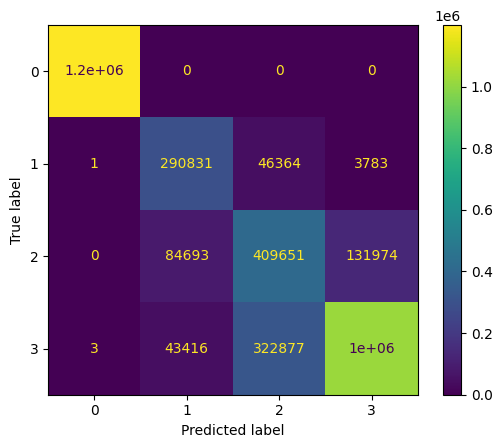

['model_lgm.pkl']

In [21]:
# === Step 8: Evaluation Metrics ===
print(" Accuracy:", accuracy_score(Y_test_fold, y_pred_labels))
print("\n Confusion Matrix:\n", confusion_matrix(Y_test_fold, y_pred_labels))
print("\nClassification Report:\n", classification_report(Y_test_fold, y_pred_labels, digits=4))

ConfusionMatrixDisplay.from_predictions(
    Y_test_fold, y_pred_labels)
plt.show()


name_lgm = "model_lgm.pkl"
joblib.dump(lgm_model, name_lgm) #401977, 0.407803

In [2]:
# prints the macro metrics per fold and per class

file= 'Reports/FCN_3Fold.txt'


# general regex patterns to locate metric blocks
patterns = {
    "F1 Measure": r"F1 Measure per Class:\s*((?:\[[^\]]+\],?\s*)+)",
    "Recall": r"Recall per Class:\s*((?:\[[^\]]+\],?\s*)+)",
    "Precision": r"Precision per Class:\s*((?:\[[^\]]+\],?\s*)+)",
    "PR AUC": r"PR AUC per Class:\s*((?:\[[^\]]+\],?\s*)+)"
}

# helper function to extract numeric arrays
def extract_arrays(block_text):
    """Extracts all bracketed numeric arrays from a text block."""
    arrays = re.findall(r"\[([^\]]+)\]", block_text)
    parsed = [np.fromstring(a.replace(",", " "), sep=" ") for a in arrays]
    return np.array(parsed)

with open(file, "r") as f:
    text = f.read()

for metric_name, pattern in patterns.items():
    match = re.search(pattern, text)
    if not match:
        continue
    arrays = extract_arrays(match.group(1))
    if arrays.size == 0:
        continue

    if metric_name == "F1 Measure":
        f1_all = arrays
    elif metric_name == "Recall":
        recall_all = arrays
    elif metric_name == "Precision":
        precision_all = arrays
    elif metric_name == "PR AUC":
        pr_auc_all = arrays

# computes summary stats
def summarize(metric, name):
    if metric.size == 0:
        print(f"\n{name}: No data found.")
        return
    mean_per_class = np.mean(metric, axis=0)
    std_per_class = np.std(metric, axis=0)
    macro_mean = np.mean(mean_per_class)
    macro_std = np.std(mean_per_class)

    print(f"\n{name} Results:")
    print(f"Mean per Class: {np.round(mean_per_class, 4)}")
    print(f"Std per Class:  {np.round(std_per_class, 4)}")
    print(f"Macro Mean: {macro_mean:.4f}, Macro Std: {macro_std:.4f}")

# summarizes all metrics
summarize(recall_all, "Recall")
summarize(precision_all, "Precision")
summarize(f1_all, "F1 Measure")
summarize(pr_auc_all, "PR AUC")


Recall Results:
Mean per Class: [1.     0.8599 0.6444 0.7317]
Std per Class:  [0.     0.0024 0.002  0.0034]
Macro Mean: 0.8090, Macro Std: 0.1343

Precision Results:
Mean per Class: [0.9997 0.6813 0.5235 0.8821]
Std per Class:  [0.0001 0.0018 0.0014 0.0017]
Macro Mean: 0.7717, Macro Std: 0.1830

F1 Measure Results:
Mean per Class: [0.9998 0.7603 0.5777 0.7999]
Std per Class:  [0.0001 0.0007 0.0004 0.0026]
Macro Mean: 0.7844, Macro Std: 0.1500

PR AUC Results:
Mean per Class: [1.     0.8509 0.566  0.9122]
Std per Class:  [0.     0.0005 0.0028 0.0017]
Macro Mean: 0.8323, Macro Std: 0.1626
